# Exploratory Data Analysis — Full Dataset
## Smartick Dataset (OpenNeuro ds006260)

Covers: psychometric scores, EEG availability, session engagement,
event tags, demographics, and recording metadata.

In [67]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import json
import warnings
warnings.filterwarnings("ignore")

%matplotlib inline
sns.set_style("whitegrid")
sns.set_context("talk")

In [68]:
ROOT = Path().resolve().parent
DATA = ROOT / "01_Psychometric_Data.xlsx"
OUT = Path().resolve() / "results" / "eda"
OUT.mkdir(parents=True, exist_ok=True)

df_reading = pd.read_excel(DATA, sheet_name="READING")
df_math = pd.read_excel(DATA, sheet_name="MATH")
df_reading.rename(columns={"GROUP": "Subgroup"}, inplace=True)
df_math.rename(columns={"GROUP": "Subgroup"}, inplace=True)

reading_dvs = ["Orthographic_ERR", "Phonological_ERR", "Selective_Attention",
                "Reading_Speed", "Comprehension"]
math_dvs = ["WRAT4", "hits", "RT", "Selective_Attention"]

# Direction: for these DVs LOWER is better (a decrease is an improvement).
# Everywhere else a higher change (POST - PRE) is better.
lower_better = {"Orthographic_ERR", "Phonological_ERR", "RT"}

def desc_table(df, dvs, group_col="Subgroup"):
    rows = []
    for grp in sorted(df[group_col].unique()):
        for session in ["PRE", "POST"]:
            for dv in dvs:
                col = f"{dv}_{session}"
                sub = df[df[group_col] == grp]
                rows.append({"Group": grp, "Session": session, "DV": dv,
                    "Mean": sub[col].mean(), "SD": sub[col].std(),
                    "Median": sub[col].median(),
                    "Min": sub[col].min(), "Max": sub[col].max(), "n": len(sub)})
    return pd.DataFrame(rows)

---
## 1. Full Cohort Demographics

In [69]:
participants = pd.read_csv(ROOT / "participants.tsv", sep="\t")

# Derive StudyGroup (R/M) and Subgroup (e/c) from participant_id
participants["StudyGroup"] = participants["participant_id"].str[4:5]  # R or M
participants["Subgroup"] = participants["Group"].map({"cont": "C", "exp": "E"})

# IQ is NOT in participants.tsv; pull it from 01_Psychometric_Data.xlsx
iq_map = pd.concat([df_reading[["Subject", "IQ"]], df_math[["Subject", "IQ"]]])
participants = participants.merge(iq_map, left_on="participant_id", right_on="Subject",
                                  how="left").drop(columns=["Subject"])

print(f"Total subjects: {len(participants)}")
print(f"\nStudy groups:")
print(participants["StudyGroup"].value_counts().rename({"R": "Reading", "M": "Math"}))
gender_ct = pd.crosstab(participants["StudyGroup"], participants["Subgroup"], margins=True)
gender_ct = gender_ct.reindex(["R", "M", "All"])
gender_ct.index = ["Reading", "Math", "Total"]
gender_ct.columns = ["Control", "Experimental", "Total"]
print(f"\nBy study group x subgroup (counts):")
print(gender_ct)
print("\nBy study group x subgroup (row %):")
print((gender_ct.astype(float).div(gender_ct["Total"], axis=0)
       .drop("Total", axis=0).mul(100).round(1).rename(columns={"Control": "C (%)", "Experimental": "E (%)"})))

print(f"\nGender overall: {participants["Gender"].value_counts().to_dict()}")
print("Gender by study group (counts + %):")
gct = pd.crosstab(participants["StudyGroup"], participants["Gender"]).loc[["R", "M"]]
gct.index = ["Reading", "Math"]
print(gct.to_string())
print((gct.astype(float).div(gct.sum(axis=1), axis=0).mul(100).round(1)).to_string())
print(f"Age overall: mean={participants["Age"].mean():.1f}, sd={participants["Age"].std():.1f}")

print(f"\nPercent of total sample (n = {len(participants)})")
print("Study group (%):")
print((participants["StudyGroup"].value_counts(normalize=True)
       .rename({"R": "Reading", "M": "Math"}).mul(100).round(1).astype(str) + "%"))
print("\nSubgroup (%):")
print((participants["Subgroup"].value_counts(normalize=True).mul(100).round(1).astype(str) + "%"))
print("\nStudy group x subgroup (% of total):")
print((pd.crosstab(participants["StudyGroup"], participants["Subgroup"], normalize="all")
       .mul(100).round(1).astype(str) + "%"))
print("\nGender (%):")
print((participants["Gender"].value_counts(normalize=True).mul(100).round(1).astype(str) + "%"))

Total subjects: 76

Study groups:
StudyGroup
Math       41
Reading    35
Name: count, dtype: int64

By study group x subgroup (counts):
         Control  Experimental  Total
Reading       16            19     35
Math          22            19     41
Total         38            38     76

By study group x subgroup (row %):
         C (%)  E (%)  Total
Reading   45.7   54.3  100.0
Math      53.7   46.3  100.0

Gender overall: {'M': 41, 'F': 35}
Gender by study group (counts + %):
Gender    F   M
Reading  16  19
Math     19  22
Gender      F     M
Reading  45.7  54.3
Math     46.3  53.7
Age overall: mean=9.9, sd=1.4

Percent of total sample (n = 76)
Study group (%):
StudyGroup
Math       53.9%
Reading    46.1%
Name: proportion, dtype: str

Subgroup (%):
Subgroup
C    50.0%
E    50.0%
Name: proportion, dtype: str

Study group x subgroup (% of total):
Subgroup        C      E
StudyGroup              
M           28.9%  25.0%
R           21.1%  25.0%

Gender (%):
Gender
M    53.9%
F    46.1%

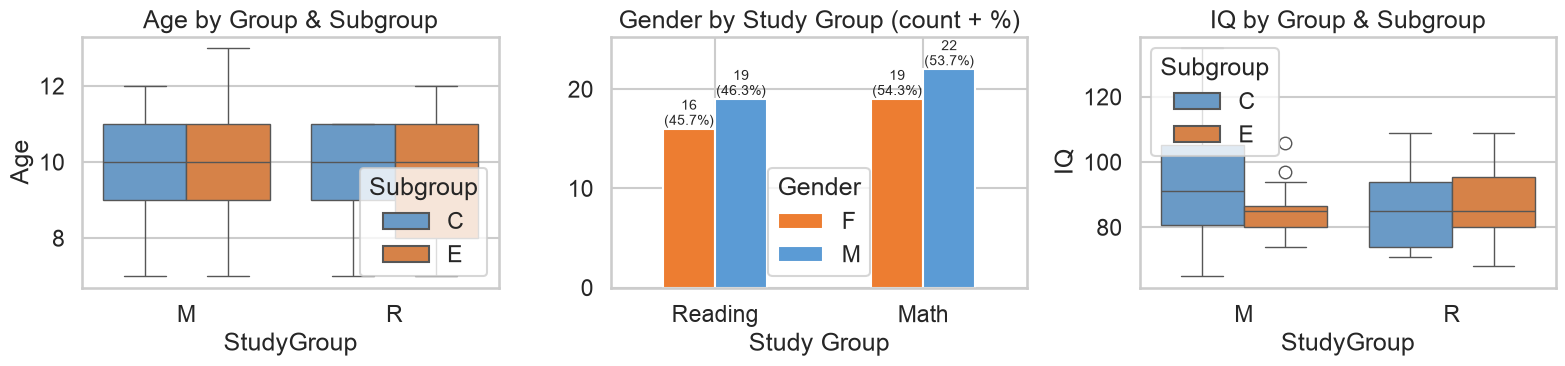

In [70]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Age by study group x subgroup
participants["GroupLabel"] = participants["StudyGroup"] + participants["Subgroup"]
sns.boxplot(data=participants, x="StudyGroup", y="Age", hue="Subgroup",
            palette={"E": "#ED7D31", "C": "#5B9BD5"}, ax=axes[0])
axes[0].set_title("Age by Group & Subgroup")

# Gender counts
gender_ct = pd.crosstab(participants["StudyGroup"], participants["Gender"]).loc[["R", "M"]]
gender_ct.index = ["Reading", "Math"]
gender_ct.plot(kind="bar", ax=axes[1], color=["#ED7D31", "#5B9BD5"])
axes[1].set_title("Gender by Study Group (count + %)")
axes[1].set_xlabel("Study Group")
axes[1].tick_params(axis="x", rotation=0)
gender_pct = gender_ct.astype(float).div(gender_ct.sum(axis=1), axis=0).mul(100)
for patch, (row, col) in zip(axes[1].patches, [(r, c) for r in gender_ct.index for c in gender_ct.columns]):
    cnt = gender_ct.loc[row, col]
    pct = gender_pct.loc[row, col]
    axes[1].annotate(f"{cnt}\n({pct:.1f}%)",
                     (patch.get_x() + patch.get_width() / 2, patch.get_height()),
                     ha="center", va="bottom", fontsize=10)
axes[1].set_ylim(0, gender_ct.max().max() * 1.15)

# IQ by study group x subgroup
sns.boxplot(data=participants, x="StudyGroup", y="IQ",
            hue="Subgroup", palette={"E": "#ED7D31", "C": "#5B9BD5"}, ax=axes[2])
axes[2].set_title("IQ by Group & Subgroup")

fig.tight_layout()
fig.savefig(OUT / "demographics_overview.png", dpi=150, bbox_inches="tight")
plt.show()

---
## 2. Psychometric Descriptives

In [71]:
tbl_r = desc_table(df_reading, reading_dvs)
tbl_r.to_csv(OUT / "descriptives_reading.csv", index=False)
tbl_r.style.set_caption("Reading DVs")

,Group,Session,DV,Mean,SD,Median,Min,Max,n
0,C,PRE,Orthographic_ERR,7.625000,4.014557,8.000000,1,14,16
1,C,PRE,Phonological_ERR,7.812500,4.929080,8.000000,0,16,16
2,C,PRE,Selective_Attention,94.312500,15.426033,96.500000,70,117,16
3,C,PRE,Reading_Speed,69.000000,23.622024,69.000000,29,126,16
4,C,PRE,Comprehension,13.250000,2.516611,13.000000,9,18,16
5,C,POST,Orthographic_ERR,6.562500,4.486554,5.000000,1,16,16
6,C,POST,Phonological_ERR,3.250000,3.587014,2.000000,0,14,16
7,C,POST,Selective_Attention,108.562500,12.925266,109.500000,84,122,16
8,C,POST,Reading_Speed,86.312500,27.202252,79.000000,48,144,16
9,C,POST,Comprehension,13.687500,2.495830,14.000000,8,18,16


In [72]:
tbl_m = desc_table(df_math, math_dvs)
tbl_m.to_csv(OUT / "descriptives_math.csv", index=False)
tbl_m.style.set_caption("Math DVs")

,Group,Session,DV,Mean,SD,Median,Min,Max,n
0,C,PRE,WRAT4,92.954545,12.369229,96.500000,68.000000,110.000000,22
1,C,PRE,hits,82.727273,11.177920,83.750000,60.000000,95.000000,22
2,C,PRE,RT,14.400801,10.333974,12.026758,3.590039,54.161914,22
3,C,PRE,Selective_Attention,97.545455,15.333522,102.000000,70.000000,118.000000,22
4,C,POST,WRAT4,100.909091,14.392158,102.500000,72.000000,121.000000,22
5,C,POST,hits,87.386364,8.946843,88.750000,62.500000,97.500000,22
6,C,POST,RT,12.943004,6.271398,11.478125,4.281445,28.533789,22
7,C,POST,Selective_Attention,106.136364,13.231620,110.500000,72.000000,126.000000,22
8,E,PRE,WRAT4,90.210526,7.420534,90.000000,73.000000,108.000000,19
9,E,PRE,hits,84.868421,9.108668,90.000000,67.500000,95.000000,19


### Baseline Equivalence (E vs C)

In [73]:
def baseline_comparison(df, dvs, label):
    rows = []
    grp_e = df[df.Subgroup == "E"]
    grp_c = df[df.Subgroup == "C"]
    for dv in ["AGE", "IQ"] + [f"{dv}_PRE" for dv in dvs]:
        vals_e = grp_e[dv].dropna()
        vals_c = grp_c[dv].dropna()
        if len(vals_e) < 2 or len(vals_c) < 2:
            continue
        stat, p = stats.mannwhitneyu(vals_e, vals_c, alternative="two-sided")
        rows.append({"Variable": dv, "Mean_E": vals_e.mean(), "Mean_C": vals_c.mean(),
                      "U": stat, "p": p})
    tbl = pd.crosstab(df.Subgroup, df.GENDER)
    chi2, p_g, _, _ = stats.chi2_contingency(tbl)
    print(f"{label} gender chi² = {chi2:.3f}, p = {p_g:.4f}")
    res = pd.DataFrame(rows)
    res.to_csv(OUT / f"baseline_{label.lower()}.csv", index=False)
    return res

baseline_comparison(df_reading, reading_dvs, "Reading")

Reading gender chi² = 0.308, p = 0.5791


,Variable,Mean_E,Mean_C,U,p
0,AGE,9.631579,9.8125,141.0,0.720509
1,IQ,87.315789,86.1250,160.5,0.790161
2,Orthographic_ERR_PRE,9.105263,7.6250,184.0,0.294401
3,Phonological_ERR_PRE,6.684211,7.8125,124.0,0.360743
4,Selective_Attention_PRE,91.947368,94.3125,137.0,0.630382
5,Reading_Speed_PRE,69.736842,69.0000,157.5,0.868452
6,Comprehension_PRE,12.000000,13.2500,110.0,0.166772


In [74]:
baseline_comparison(df_math, math_dvs, "Math")

Math gender chi² = 0.191, p = 0.6624


,Variable,Mean_E,Mean_C,U,p
0,AGE,10.210526,9.863636,235.5,0.488972
1,IQ,85.368421,95.272727,142.5,0.081902
2,WRAT4_PRE,90.210526,92.954545,168.5,0.295244
3,hits_PRE,84.868421,82.727273,222.0,0.742021
4,RT_PRE,13.622995,14.400801,208.0,0.989570
5,Selective_Attention_PRE,93.842105,97.545455,179.0,0.439956


### PRE vs POST Change (paired Wilcoxon)

Paired Wilcoxon signed-rank test of within-subject change (POST − PRE) for each DV,
separately within Control (C) and Experimental (E).

In [75]:
def prepost_comparison(df, dvs, label):
    rows = []
    for grp in ["E", "C"]:
        sub = df[df.Subgroup == grp]
        for dv in dvs:
            delta = (sub[f"{dv}_POST"] - sub[f"{dv}_PRE"]).dropna()
            if len(delta) < 2:
                continue
            W, p = stats.wilcoxon(delta)
            rows.append({"Group": grp, "Variable": dv,
                         "Mean_PRE": sub.loc[delta.index, f"{dv}_PRE"].mean(),
                         "Mean_POST": sub.loc[delta.index, f"{dv}_POST"].mean(),
                         "Mean_Change": delta.mean(), "W": W, "p": p, "n": len(delta)})
    res = pd.DataFrame(rows)
    res = res.round(4)
    res.to_csv(OUT / f"prepost_{label.lower()}.csv", index=False)
    return res

prepost_comparison(df_reading, reading_dvs, "Reading")

,Group,Variable,Mean_PRE,Mean_POST,Mean_Change,W,p,n
0,E,Orthographic_ERR,9.1053,7.3158,-1.7895,6.5,0.0062,19
1,E,Phonological_ERR,6.6842,3.0526,-3.6316,18.0,0.0096,19
2,E,Selective_Attention,91.9474,102.3684,10.4211,14.0,0.0011,19
3,E,Reading_Speed,69.7368,85.0526,15.3158,1.0,0.0002,19
4,E,Comprehension,12.0000,13.7895,1.7895,22.0,0.0303,19
5,C,Orthographic_ERR,7.6250,6.5625,-1.0625,34.5,0.1460,16
6,C,Phonological_ERR,7.8125,3.2500,-4.5625,1.5,0.0013,16
7,C,Selective_Attention,94.3125,108.5625,14.2500,4.0,0.0015,16
8,C,Reading_Speed,69.0000,86.3125,17.3125,10.5,0.0029,16
9,C,Comprehension,13.2500,13.6875,0.4375,37.5,0.5748,16


In [76]:
prepost_comparison(df_math, math_dvs, "Math")

,Group,Variable,Mean_PRE,Mean_POST,Mean_Change,W,p,n
0,E,WRAT4,90.2105,96.9474,6.7368,43.0,0.0362,19
1,E,hits,84.8684,87.8947,3.0263,47.0,0.2754,19
2,E,RT,13.6230,11.2634,-2.3596,49.0,0.0663,19
3,E,Selective_Attention,93.8421,108.8421,15.0000,2.0,0.0002,19
4,C,WRAT4,92.9545,100.9091,7.9545,59.0,0.0283,22
5,C,hits,82.7273,87.3864,4.6591,31.0,0.0172,22
6,C,RT,14.4008,12.9430,-1.4578,95.0,0.3209,22
7,C,Selective_Attention,97.5455,106.1364,8.5909,35.0,0.0030,22


### Paired Box + Strip Plots (PRE vs POST by group)

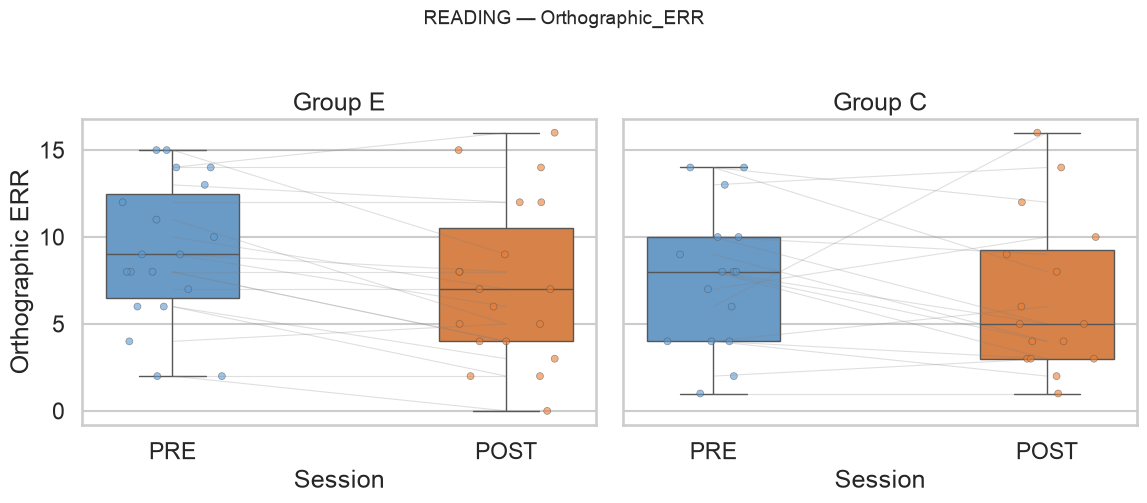

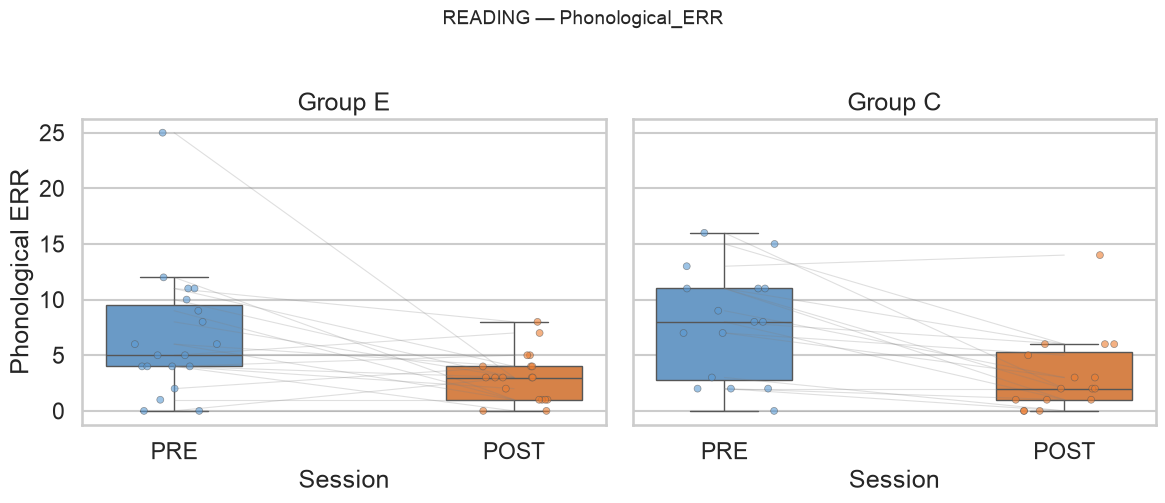

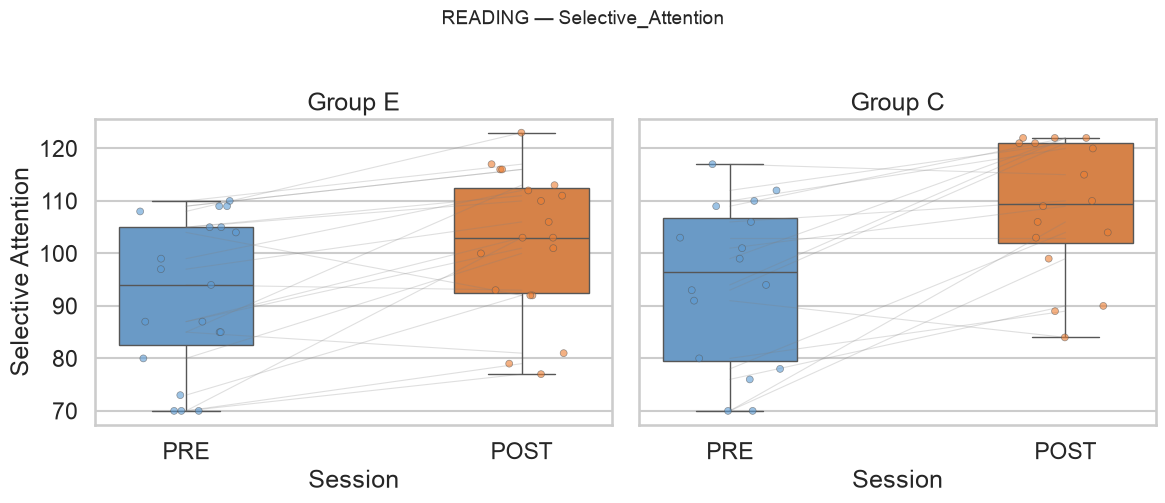

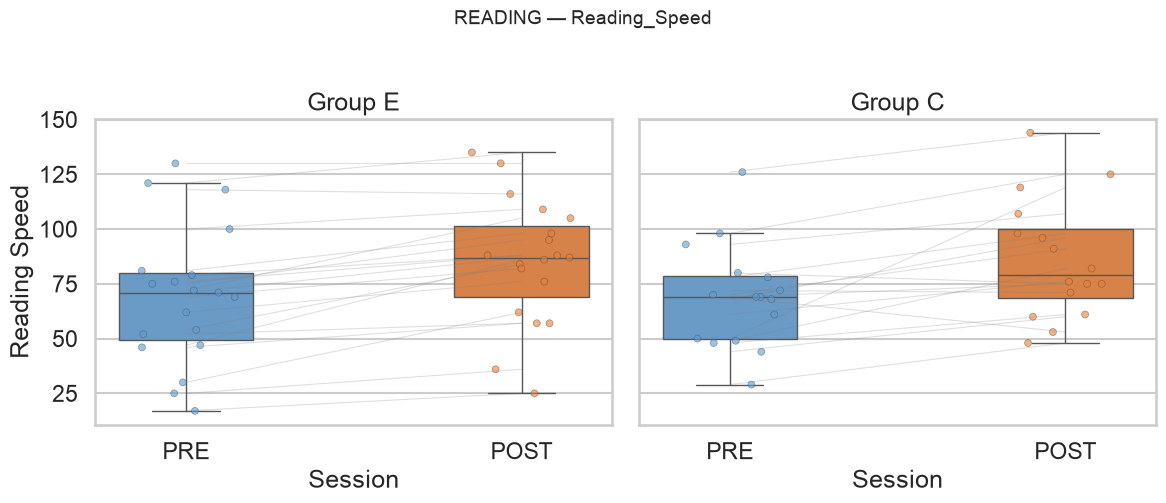

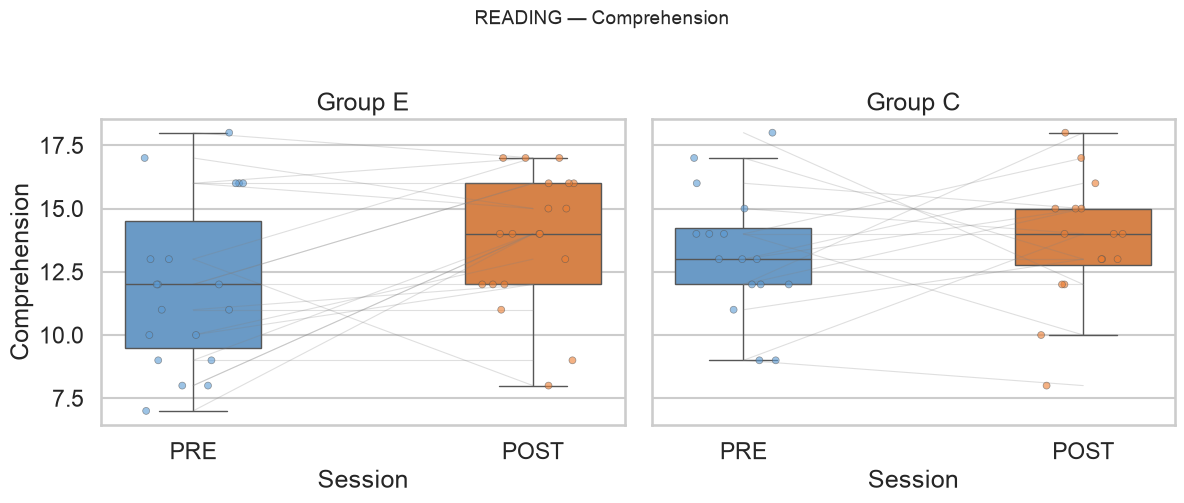

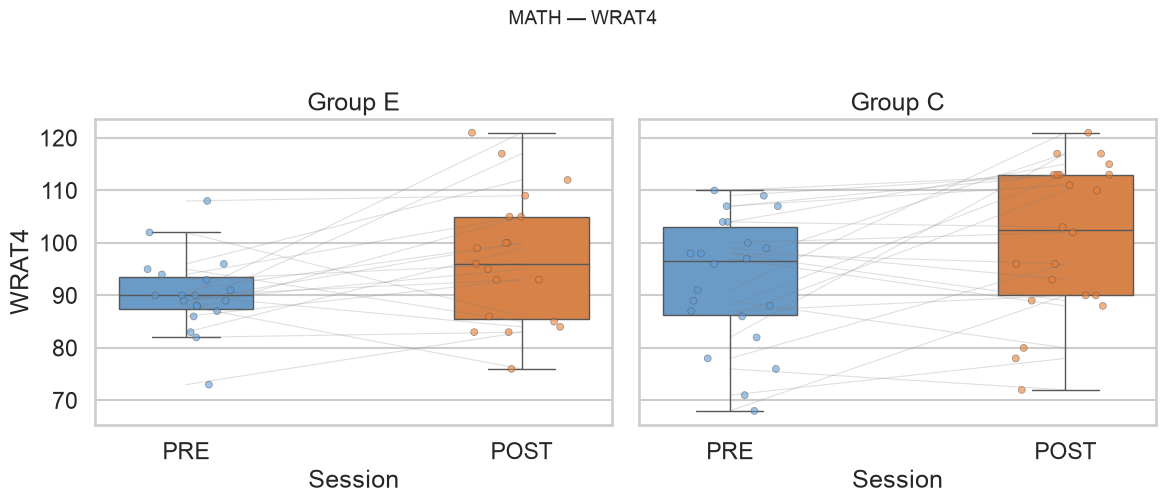

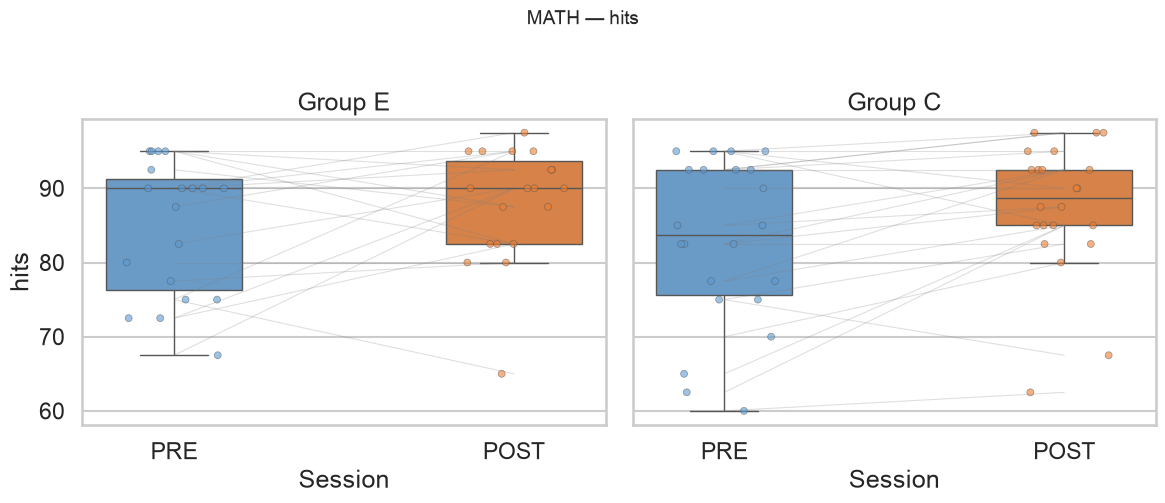

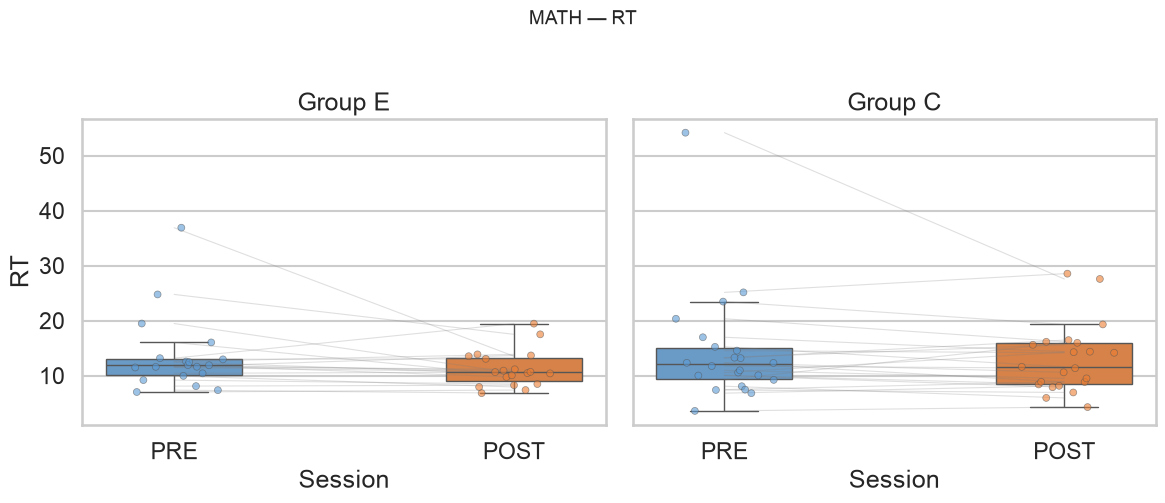

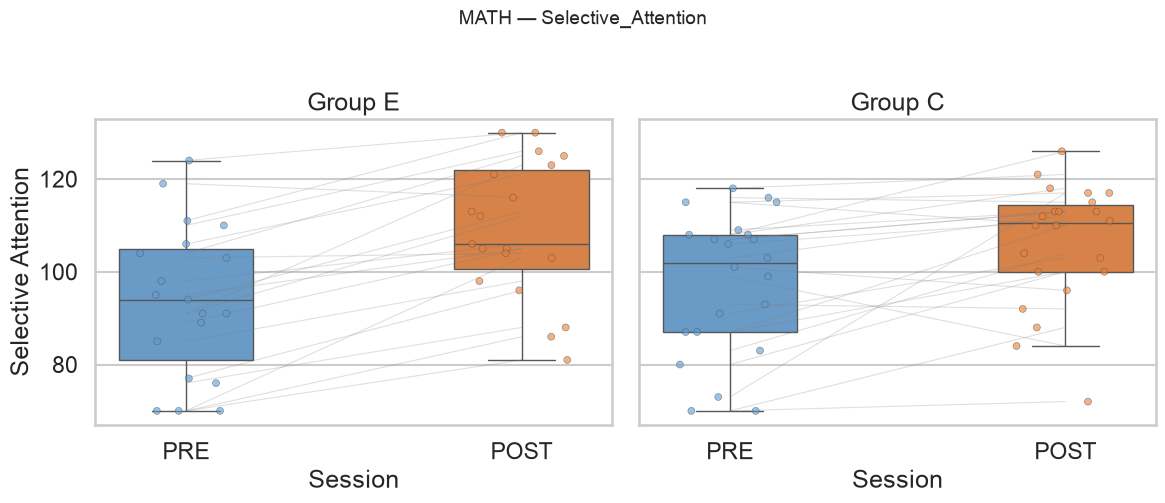

In [77]:
for name, df, dvs in [("reading", df_reading, reading_dvs), ("math", df_math, math_dvs)]:
    for dv in dvs:
        fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
        for i, grp in enumerate(["E", "C"]):
            ax = axes[i]
            sub = df[df.Subgroup == grp].copy()
            melted = sub.melt(id_vars=["Subject"],
                value_vars=[f"{dv}_PRE", f"{dv}_POST"],
                var_name="Session", value_name=dv)
            melted["Session"] = melted["Session"].str.extract(r"(PRE|POST)")
            sns.boxplot(data=melted, x="Session", y=dv, ax=ax,
                palette={"PRE": "#5B9BD5", "POST": "#ED7D31"}, width=0.4, fliersize=0)
            sns.stripplot(data=melted, x="Session", y=dv, ax=ax,
                palette={"PRE": "#5B9BD5", "POST": "#ED7D31"},
                size=5, alpha=0.6, jitter=0.15, edgecolor="gray", linewidth=0.5)
            for _, row in sub.iterrows():
                ax.plot([0, 1], [row[f"{dv}_PRE"], row[f"{dv}_POST"]],
                    color="gray", alpha=0.25, linewidth=0.8)
            ax.set_title(f"Group {grp}")
            ax.set_ylabel(dv.replace("_", " "))
        fig.suptitle(f"{name.upper()} \u2014 {dv}", fontsize=14, y=1.02)
        fig.tight_layout()
        fig.savefig(OUT / f"boxplot_{name}_{dv}.png", dpi=150, bbox_inches="tight")
        plt.show()

### Change Score (POST − PRE) Distributions

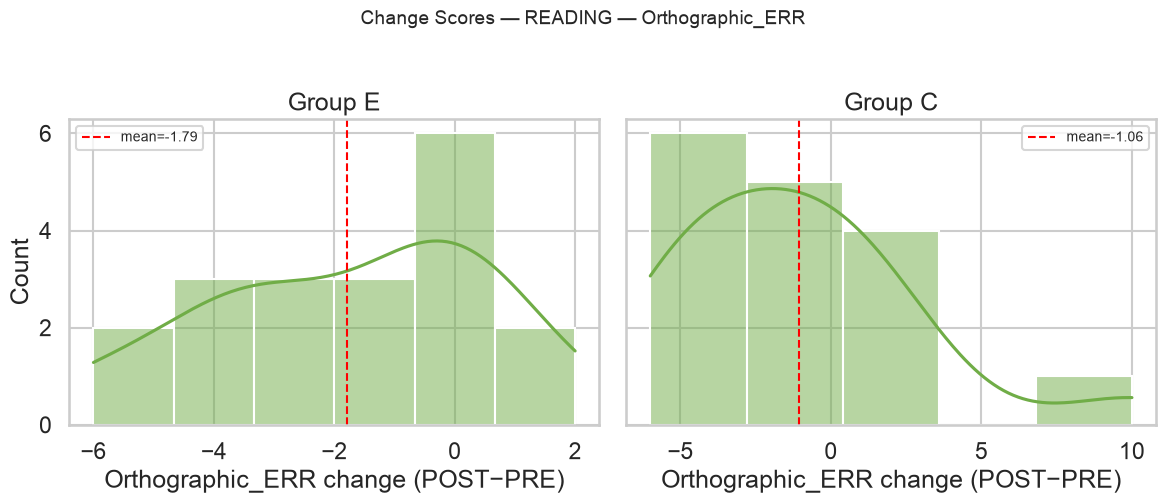

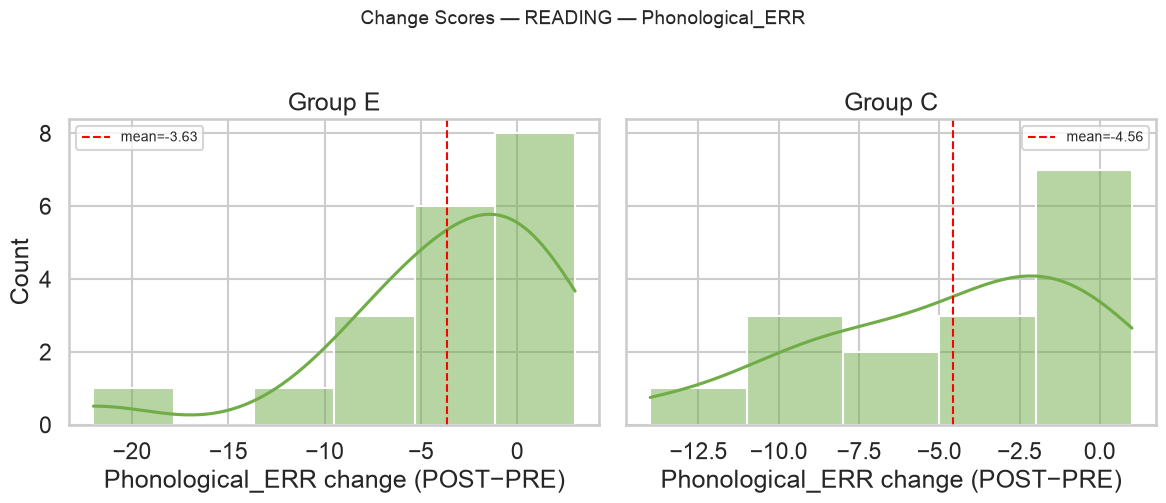

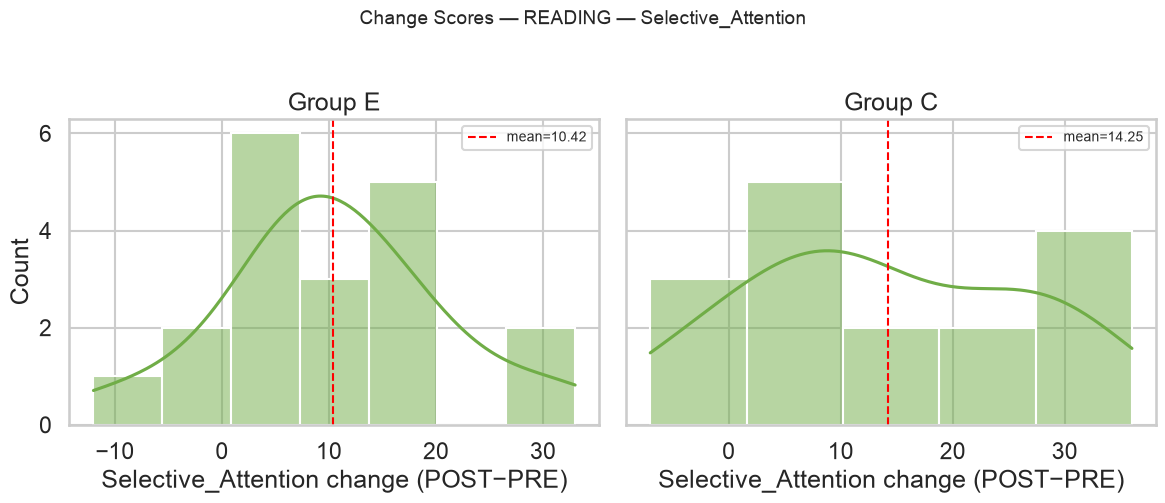

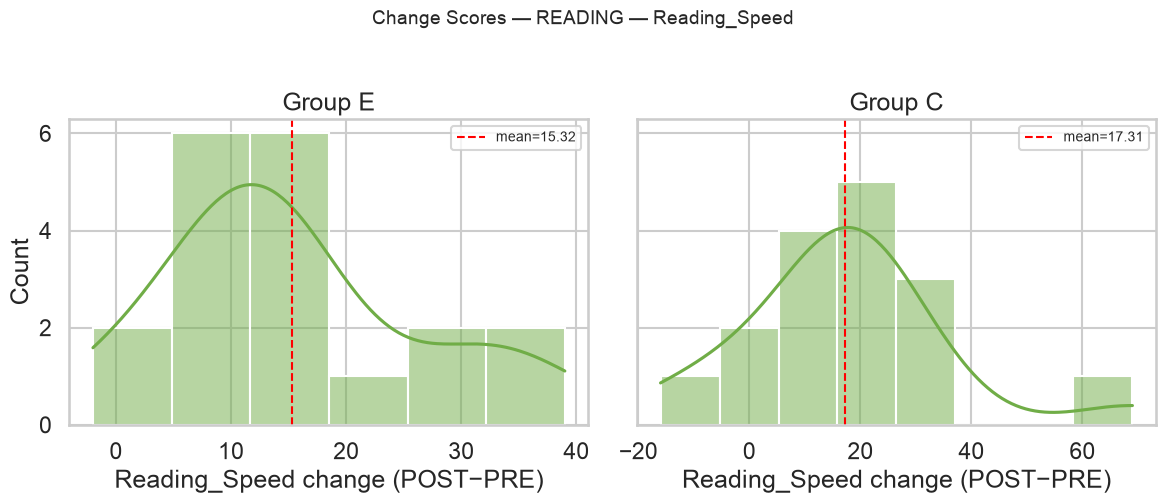

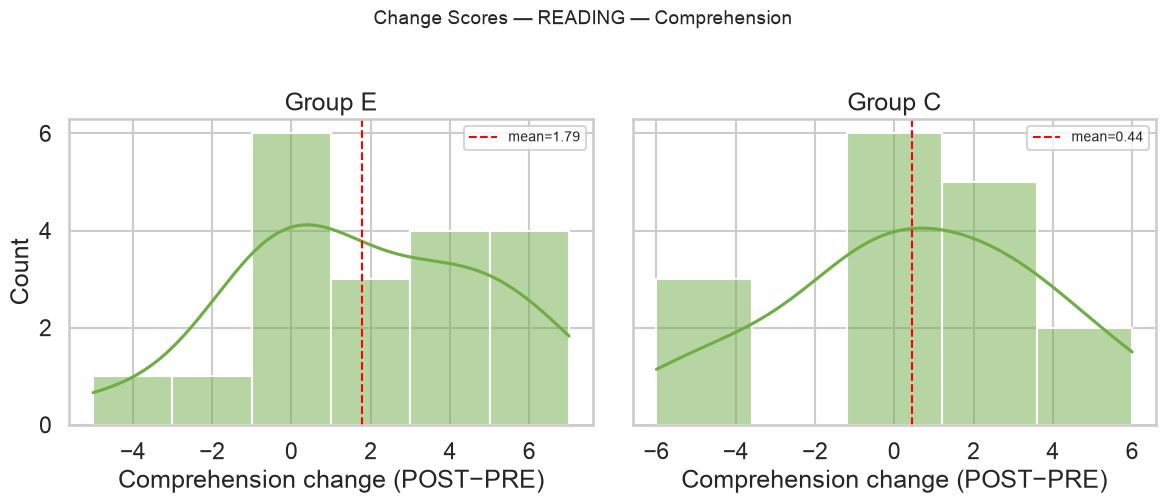

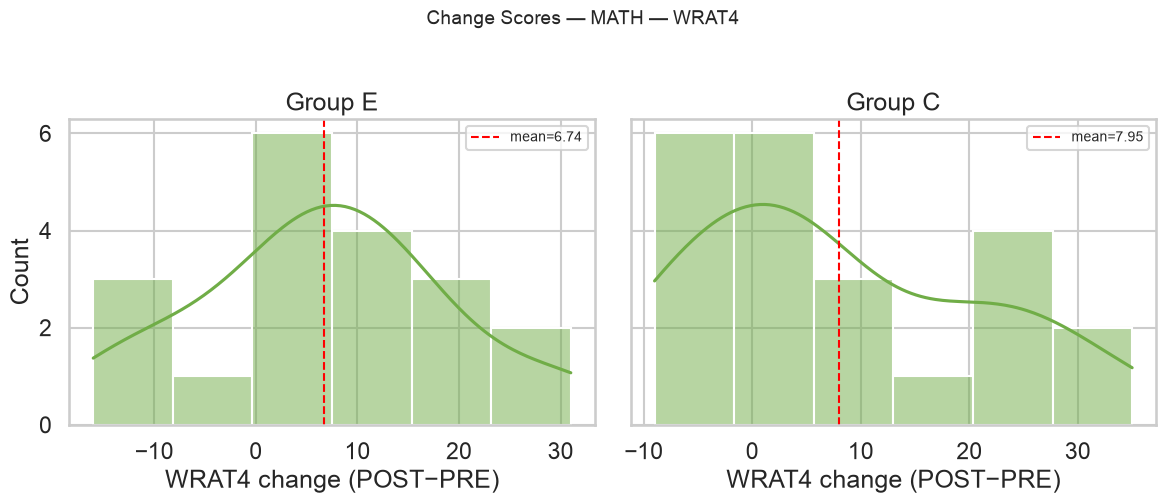

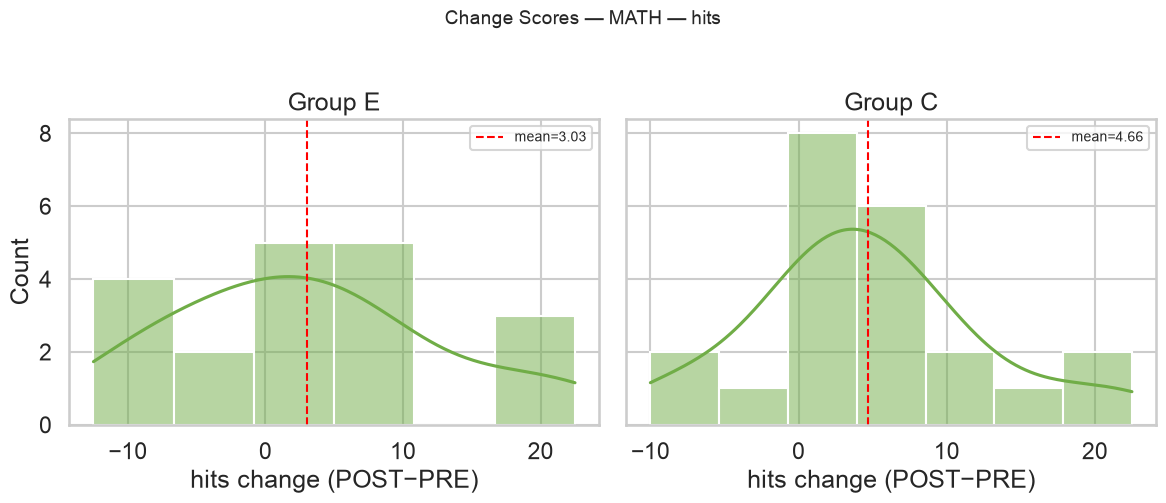

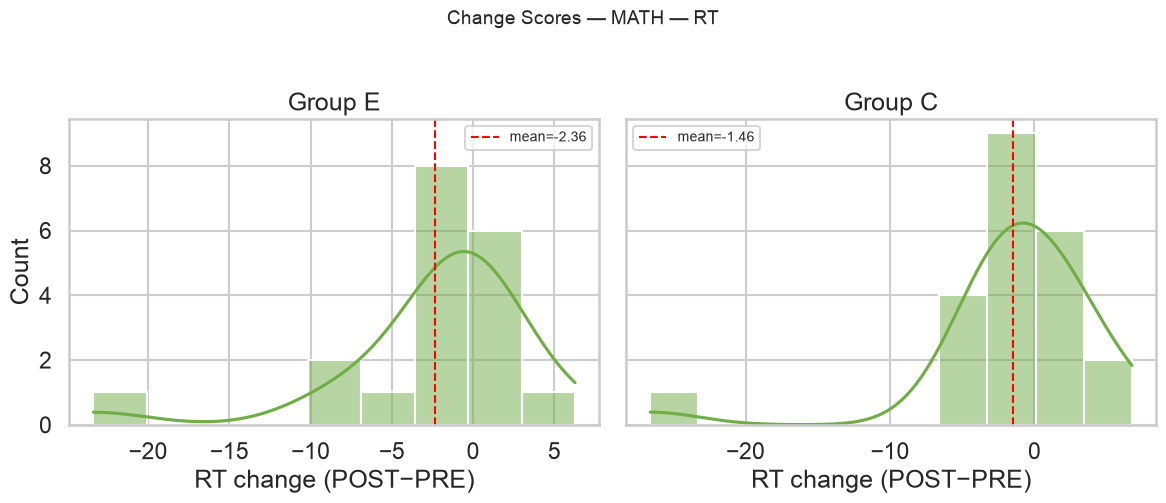

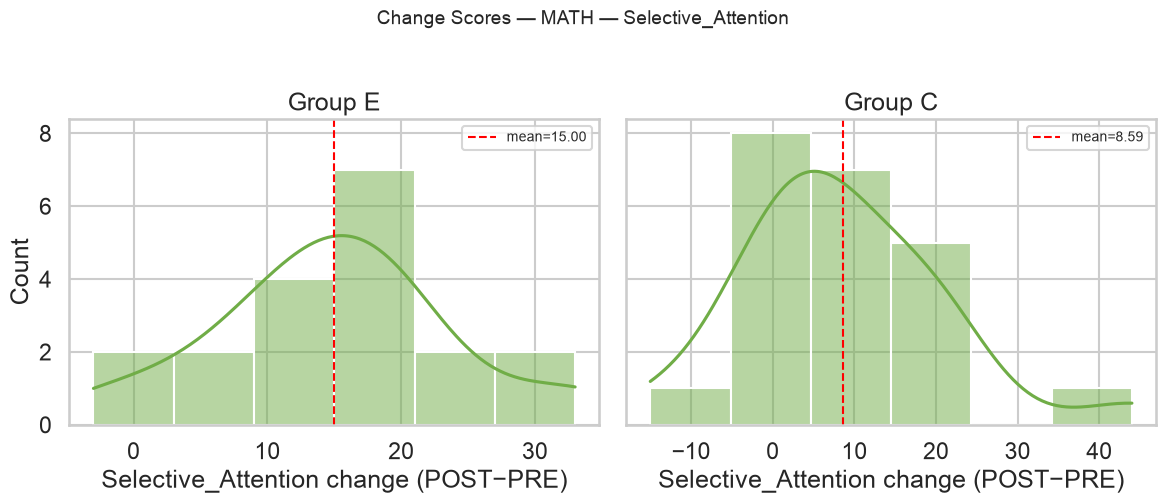

In [78]:
for name, df, dvs in [("reading", df_reading, reading_dvs), ("math", df_math, math_dvs)]:
    for dv in dvs:
        fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
        for i, grp in enumerate(["E", "C"]):
            ax = axes[i]
            sub = df[df.Subgroup == grp]
            delta = sub[f"{dv}_POST"] - sub[f"{dv}_PRE"]
            sns.histplot(delta, kde=True, ax=ax, color="#70AD47", edgecolor="white")
            ax.axvline(delta.mean(), color="red", ls="--", lw=1.5,
                       label=f"mean={delta.mean():.2f}")
            ax.legend(fontsize=10)
            ax.set_title(f"Group {grp}")
            ax.set_xlabel(f"{dv} change (POST\u2212PRE)")
        fig.suptitle(f"Change Scores \u2014 {name.upper()} \u2014 {dv}", fontsize=14, y=1.02)
        fig.tight_layout()
        fig.savefig(OUT / f"change_{name}_{dv}.png", dpi=150, bbox_inches="tight")
        plt.show()

### Change Score (POST − PRE) — C vs E by DV

Boxplots comparing the within-subject change (POST − PRE) between Control and Experimental
directly, per DV. E vs C tested with Mann–Whitney U.

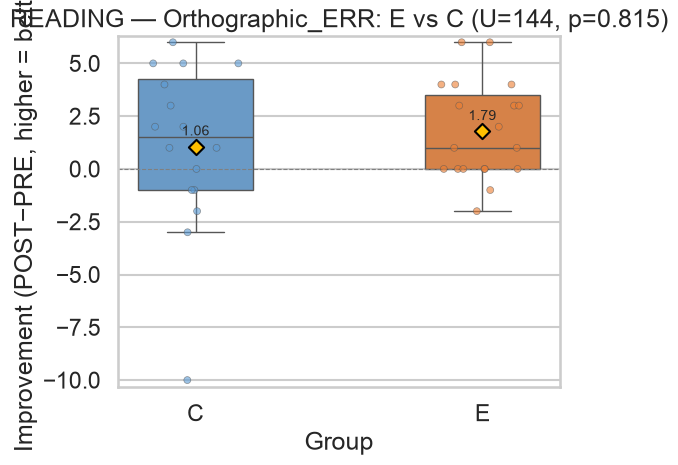

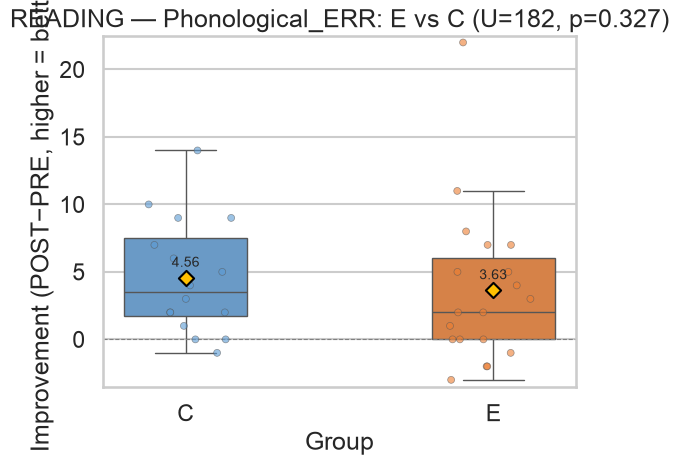

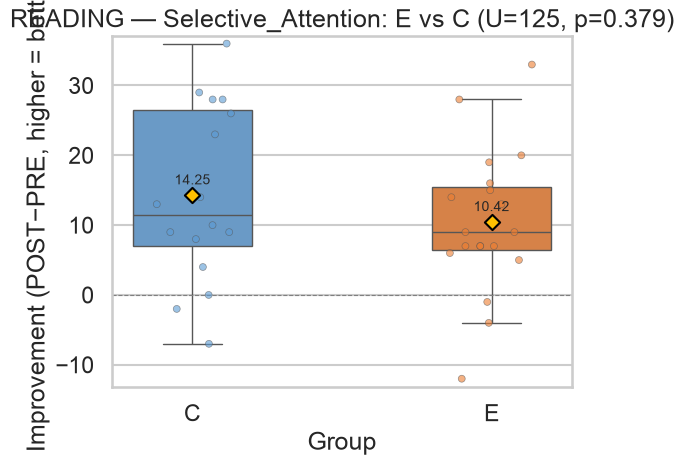

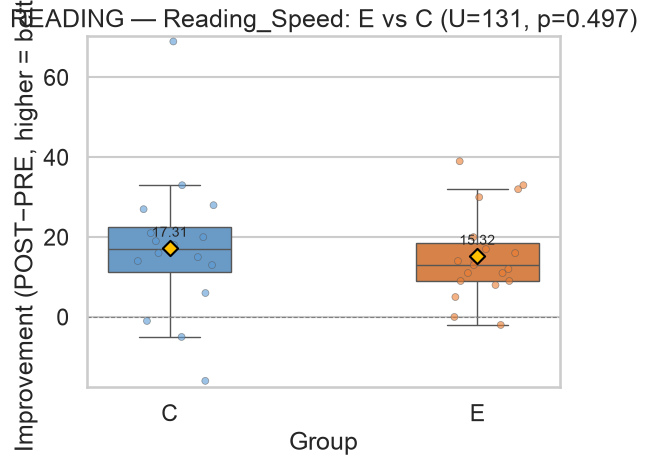

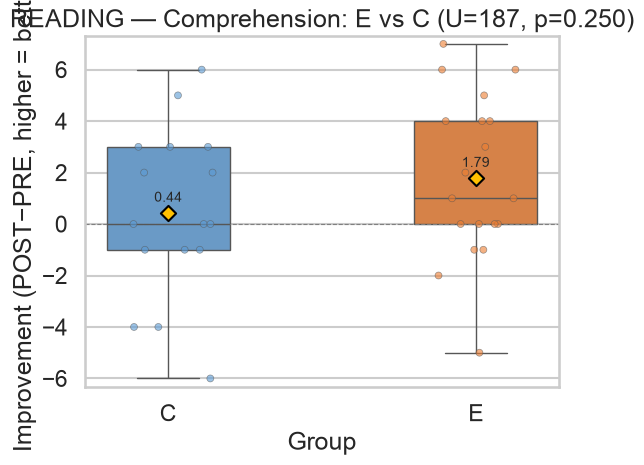

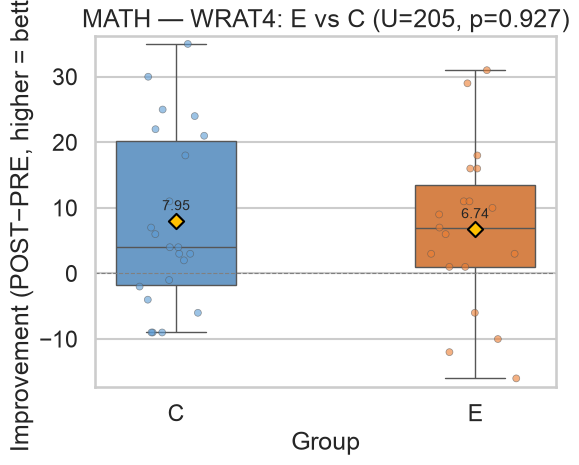

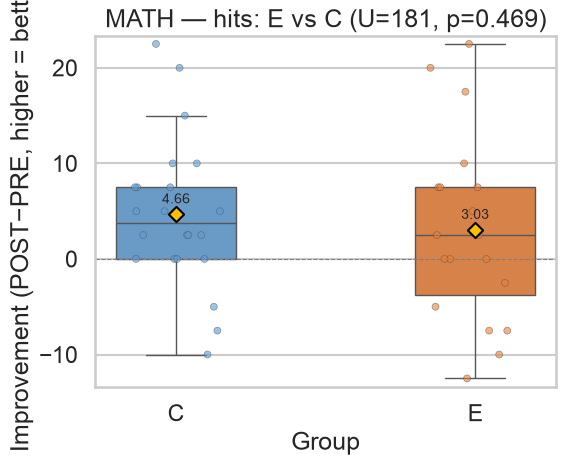

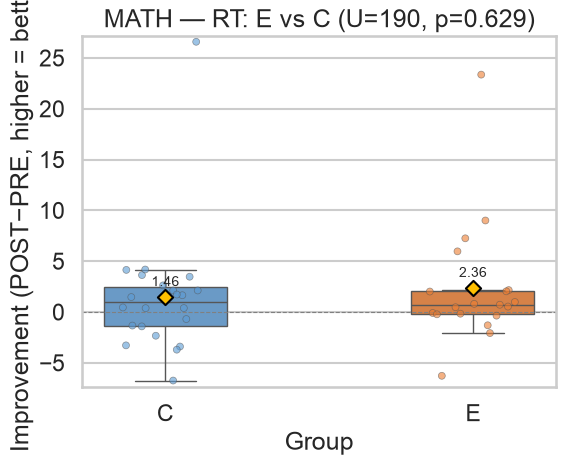

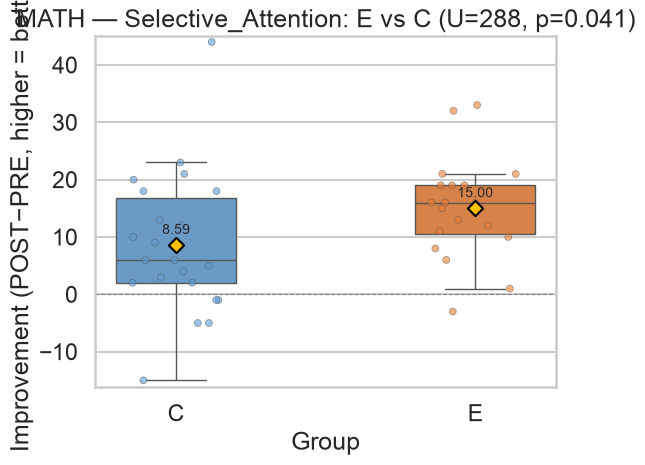

In [79]:
for name, df, dvs in [("reading", df_reading, reading_dvs), ("math", df_math, math_dvs)]:
    rows = []
    for dv in dvs:
        tmp = df[["Subject", "Subgroup", f"{dv}_PRE", f"{dv}_POST"]].copy()
        tmp["Change"] = tmp[f"{dv}_POST"] - tmp[f"{dv}_PRE"]
        direction = -1 if dv in lower_better else 1
        tmp["Improvement"] = direction * tmp["Change"]   # higher = better
        tmp = tmp.dropna(subset=["Change"])
        vals_e = tmp.loc[tmp.Subgroup == "E", "Change"]
        vals_c = tmp.loc[tmp.Subgroup == "C", "Change"]
        imp_e = tmp.loc[tmp.Subgroup == "E", "Improvement"]
        imp_c = tmp.loc[tmp.Subgroup == "C", "Improvement"]
        U, p = stats.mannwhitneyu(vals_e, vals_c)
        rows.append({"DV": dv, "Direction": "lower_better" if dv in lower_better else "higher_better",
                     "Mean_E": vals_e.mean(), "Mean_C": vals_c.mean(),
                     "E_minus_C": vals_e.mean() - vals_c.mean(),
                     "Improvement_E": imp_e.mean(), "Improvement_C": imp_c.mean(),
                     "Improv_E_minus_C": imp_e.mean() - imp_c.mean(),
                     "U": U, "p": p, "n_E": len(vals_e), "n_C": len(vals_c)})

        fig, ax = plt.subplots(figsize=(6, 5))
        ax.set_ylim(tmp["Improvement"].min() - 0.1 * abs(tmp["Improvement"].std()),
                    tmp["Improvement"].max() + 0.1 * abs(tmp["Improvement"].std()))
        sns.boxplot(data=tmp, x="Subgroup", y="Improvement", order=["C", "E"],
                    palette={"C": "#5B9BD5", "E": "#ED7D31"}, width=0.4, fliersize=0, ax=ax)
        sns.stripplot(data=tmp, x="Subgroup", y="Improvement", order=["C", "E"],
                      palette={"C": "#5B9BD5", "E": "#ED7D31"},
                      size=5, alpha=0.6, jitter=0.15, edgecolor="gray", linewidth=0.5, ax=ax)
        ax.axhline(0, color="gray", lw=0.8, ls="--")
        for grp, pos in [("C", 0), ("E", 1)]:
            m = tmp.loc[tmp.Subgroup == grp, "Improvement"].mean()
            ax.scatter(pos, m, marker="D", s=60, color="#FFC000", edgecolor="black", zorder=5)
            ax.annotate(f"{m:.2f}", (pos, m), textcoords="offset points",
                        xytext=(0, 8), ha="center", fontsize=10)
        ax.set_ylabel("Improvement (POST\u2212PRE, higher = better)")
        ax.set_xlabel("Group")
        ax.set_title(f"{name.upper()} \u2014 {dv}: E vs C (U={U:.0f}, p={p:.3f})")
        fig.tight_layout()
        fig.savefig(OUT / f"change_box_{name}_{dv}.png", dpi=150, bbox_inches="tight")
        plt.show()

    res = pd.DataFrame(rows)
    res = res.round(4)
    res.to_csv(OUT / f"change_e_vs_c_{name}.csv", index=False)
    res

### MANOVA — Joint PRE → POST Change

Tests whether all DVs **change jointly** from PRE to POST:

- **Within each subgroup (E, C)**: Hotelling's T² on the vector of change scores (POST − PRE);
  H₀: the joint change vector equals zero.
- **Between groups (E vs C)**: one-way MANOVA (statsmodels, Wilks' λ) on the change vectors;
  H₀: the joint change does not differ between experimental and control.

In [80]:
from statsmodels.multivariate.manova import MANOVA

def hotelling_t2(diff):
    """Hotelling's T2 test against H0: mean change vector = 0.
    diff: (n, p) DataFrame of POST - PRE per DV."""
    diff = diff.dropna(how="any")
    n, p = diff.shape
    if n <= p:
        return n, np.nan, np.nan, np.nan
    mean = diff.mean(axis=0)
    Sinv = np.linalg.pinv(np.cov(diff, rowvar=False))
    T2 = n * mean.to_numpy() @ Sinv @ mean.to_numpy()
    F = (n - p) / (p * (n - 1)) * T2
    pval = 1 - stats.f.cdf(F, p, n - p)
    return n, T2, F, pval

rows = []
for name, df, dvs in [("reading", df_reading, reading_dvs), ("math", df_math, math_dvs)]:
    pre_cols = [f"{dv}_PRE" for dv in dvs]
    post_cols = [f"{dv}_POST" for dv in dvs]

    # Within-group: paired Hotelling T2 on change vectors
    for grp in ["E", "C"]:
        sub = df[df.Subgroup == grp]
        diff = pd.DataFrame(sub[post_cols].to_numpy() - sub[pre_cols].to_numpy(),
                            columns=dvs)
        n, T2, F, pval = hotelling_t2(diff)
        rows.append({"StudyGroup": name, "Test": f"{grp} within (PRE vs POST)",
                     "Method": "Hotelling_T2", "n": n, "Value": T2, "F": F,
                     "p": pval})

    # Between-group: MANOVA on change vectors
    d = df.copy()
    for dv in dvs:
        d[f"chg_{dv}"] = d[f"{dv}_POST"] - d[f"{dv}_PRE"]
    md = d[["Subgroup"] + [f"chg_{dv}" for dv in dvs]].dropna(how="any")
    formula = " + ".join(f"chg_{dv}" for dv in dvs) + " ~ C(Subgroup)"
    mv = MANOVA.from_formula(formula, data=md)
    stat = mv.mv_test()["C(Subgroup)"]["stat"]
    lam = stat.loc["Wilks' lambda"]
    rows.append({"StudyGroup": name, "Test": "E vs C (change vector)",
                 "Method": "MANOVA_Wilks", "n": len(md), "Value": lam["Value"],
                 "F": lam["F Value"], "p": lam["Pr > F"]})

res_manova = pd.DataFrame(rows)
res_manova[["Value", "F"]] = res_manova[["Value", "F"]].round(4)
res_manova["p"] = res_manova["p"].round(4)
res_manova.to_csv(OUT / "manova_prepost.csv", index=False)
res_manova

,StudyGroup,Test,Method,n,Value,F,p
0,reading,E within (PRE vs POST),Hotelling_T2,19,46.4588,7.2269,0.0015
1,reading,C within (PRE vs POST),Hotelling_T2,16,96.9855,14.2245,0.0002
2,reading,E vs C (change vector),MANOVA_Wilks,35,0.8675,0.8861,0.5030
3,math,E within (PRE vs POST),Hotelling_T2,19,101.2008,21.0835,0.0000
4,math,C within (PRE vs POST),Hotelling_T2,22,35.5796,7.6242,0.0009
5,math,E vs C (change vector),MANOVA_Wilks,41,0.8922,1.0878,0.3772


### MANOVA — Joint Change Plot

Visualizes the joint PRE → POST change per cohort (2 panels per cohort):

- **Left**: standardized mean change (POST − PRE, in pooled PRE-SD units) per DV,
  side by side for C and E; a joint shift off the zero line reflects within-group Hotelling T².
- **Right**: PCA projection of the subject change vectors with 95% confidence ellipses
  for C and E; ellipse separation reflects the E-vs-C MANOVA (Wilks' λ).

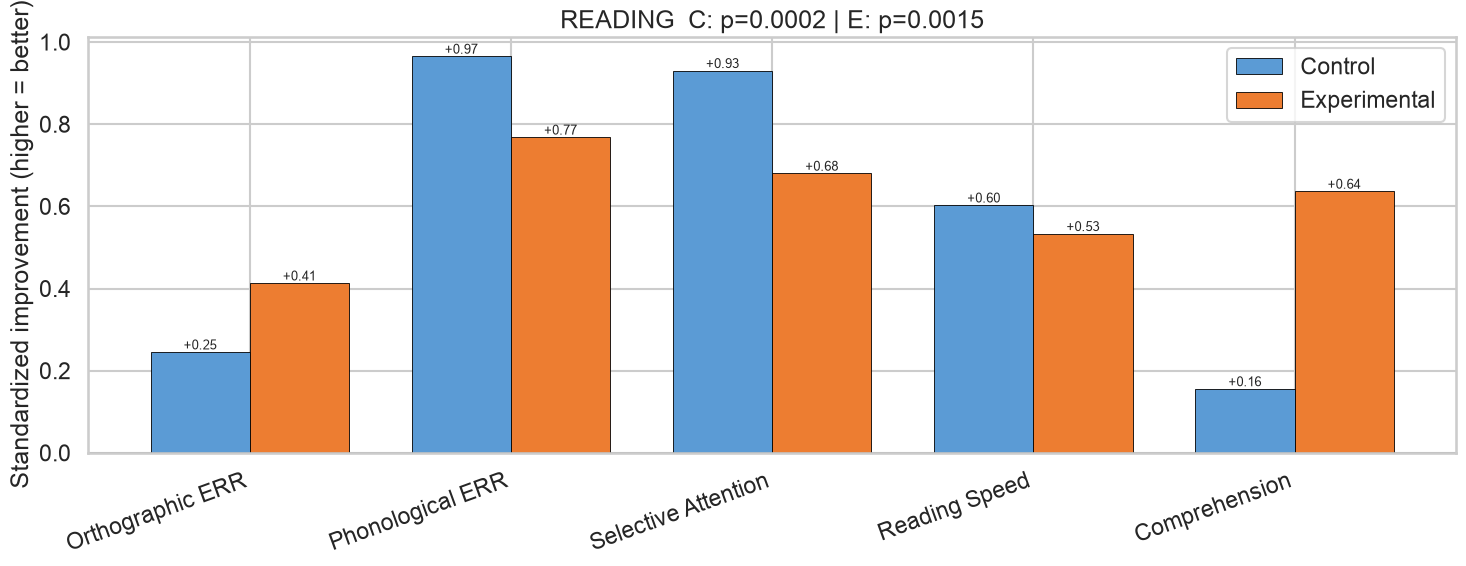

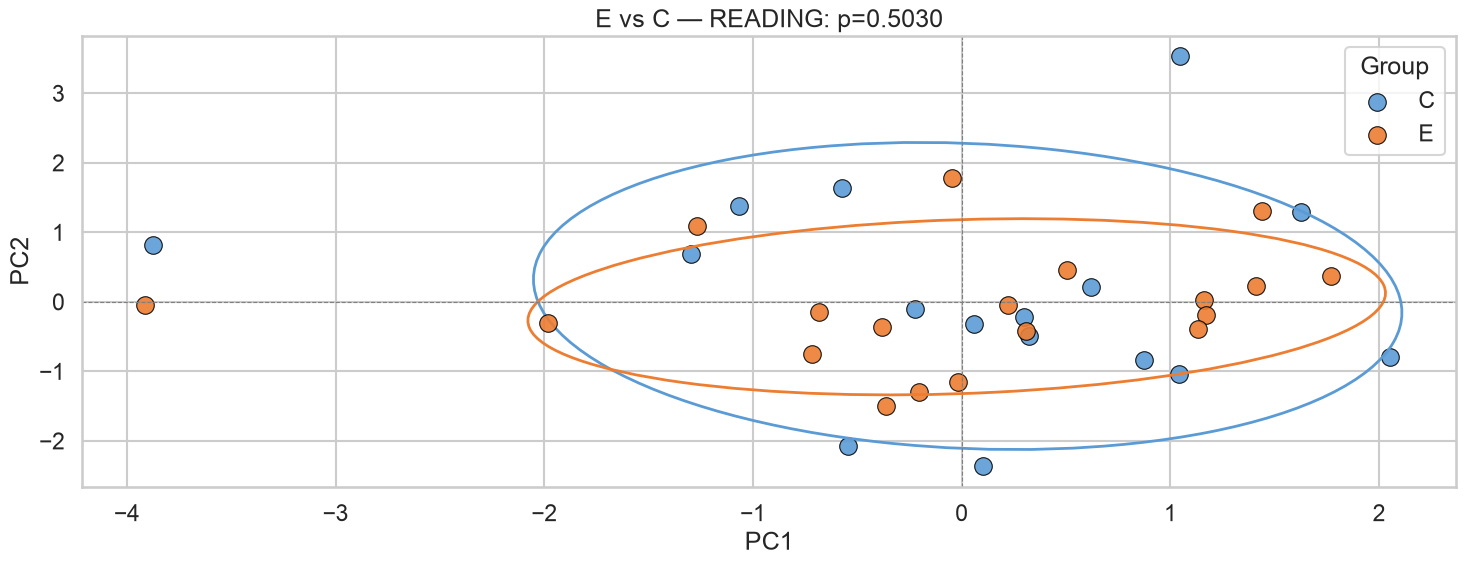

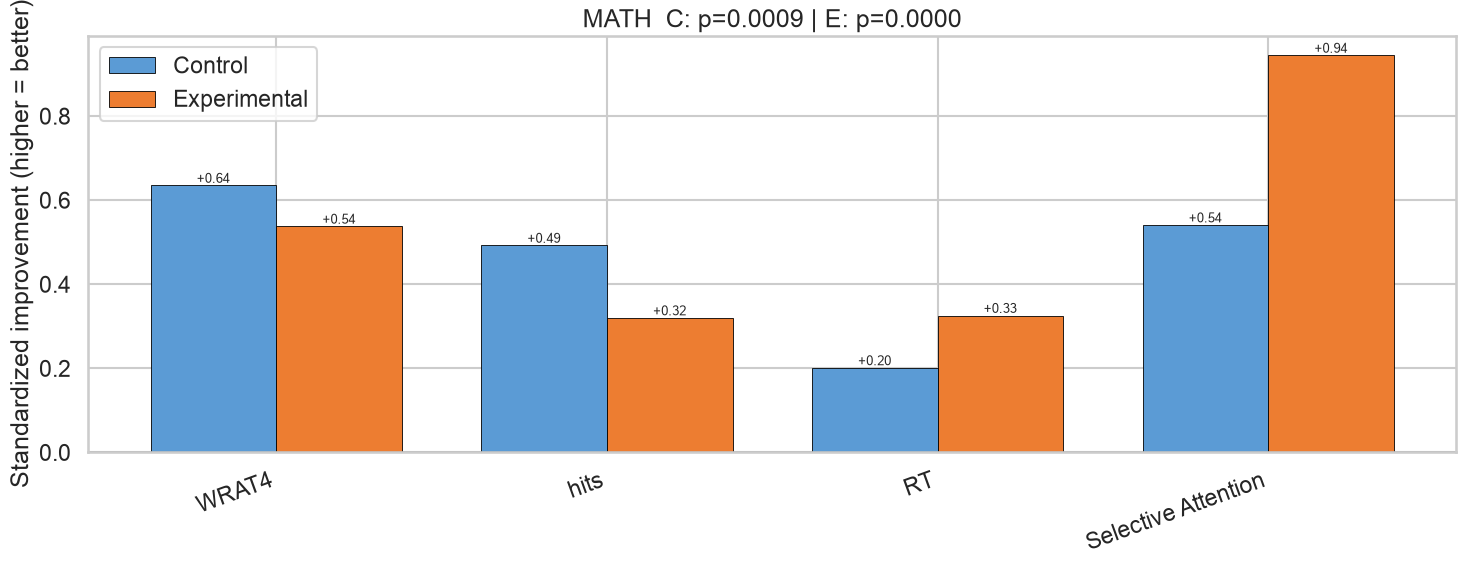

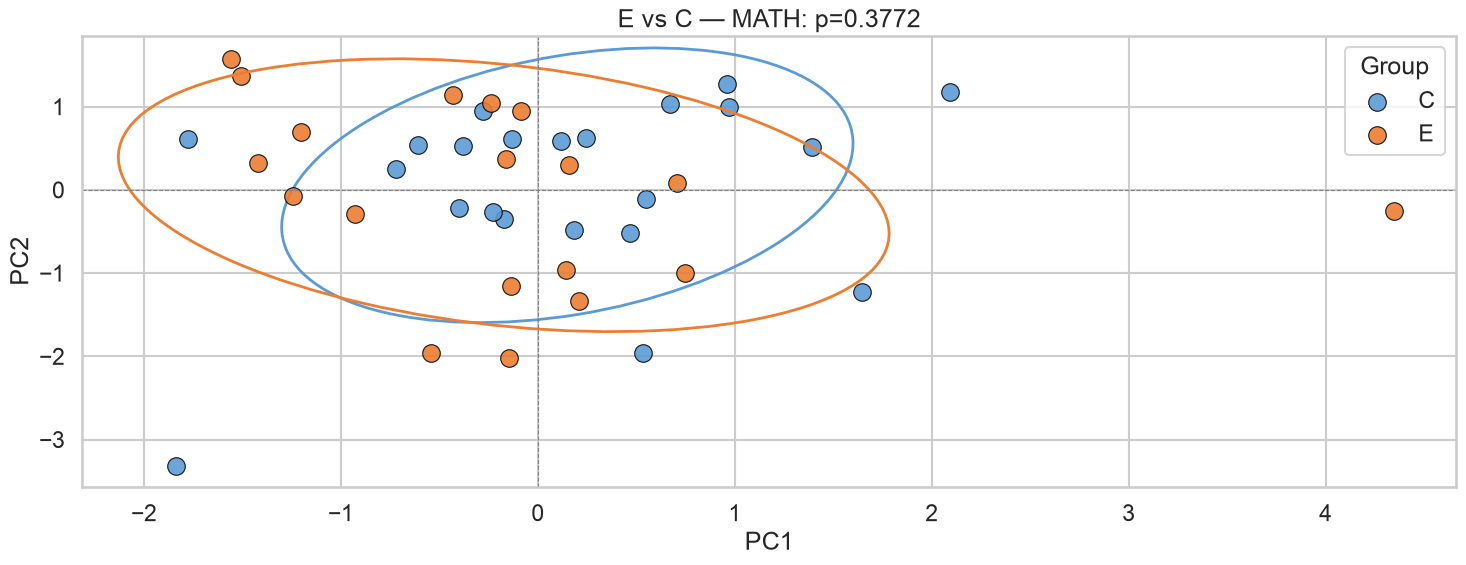

In [81]:
def conf_ellipse(ax, x, y, color, n_std=1.5, **kw):
    from matplotlib.patches import Ellipse
    cov = np.cov(x, y)
    vals, vecs = np.linalg.eigh(cov)
    order = vals.argsort()[::-1]
    vals, vecs = vals[order], vecs[:, order]
    theta = np.degrees(np.arctan2(*vecs[:, 0][::-1]))
    w, h = 2 * n_std * np.sqrt(vals)
    ax.add_patch(Ellipse((x.mean(), y.mean()), w, h, angle=theta,
                         fill=False, lw=2, edgecolor=color, **kw))

for name, df, dvs in [("reading", df_reading, reading_dvs), ("math", df_math, math_dvs)]:
    grp_e = df[df.Subgroup == "E"]
    grp_c = df[df.Subgroup == "C"]
    spec = res_manova[res_manova["StudyGroup"] == name]
    p_E = spec[spec["Test"] == "E within (PRE vs POST)"]["p"].iloc[0]
    p_C = spec[spec["Test"] == "C within (PRE vs POST)"]["p"].iloc[0]
    p_bet = spec[spec["Test"] == "E vs C (change vector)"]["p"].iloc[0]

    fig, axes = plt.subplots(figsize=(15, 6))

    # Left: standardized mean change per DV, C vs E
    dvs_short = [dv.replace("_", " ") for dv in dvs]
    std_change_e, std_change_c, pooled_sd = [], [], []
    for dv in dvs:
        direction = -1 if dv in lower_better else 1
        vals_e = (grp_e[f"{dv}_POST"] - grp_e[f"{dv}_PRE"]).dropna()
        vals_c = (grp_c[f"{dv}_POST"] - grp_c[f"{dv}_PRE"]).dropna()
        sd_pool = df[[f"{dv}_PRE", f"{dv}_POST"]].values.std(ddof=1)
        pooled_sd.append(sd_pool)
        std_change_e.append(direction * vals_e.mean() / sd_pool)
        std_change_c.append(direction * vals_c.mean() / sd_pool)
    x = np.arange(len(dvs))
    w = 0.38
    b1 = axes.bar(x - w / 2, std_change_c, w, color="#5B9BD5",
                     edgecolor="black", linewidth=0.6, label="Control")
    b2 = axes.bar(x + w / 2, std_change_e, w, color="#ED7D31",
                     edgecolor="black", linewidth=0.6, label="Experimental")
    axes.axhline(0, color="black", lw=1)
    for bar in list(b1) + list(b2):
        axes.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
                     f"{bar.get_height():+.2f}", ha="center", va="bottom", fontsize=9)
    axes.set_xticks(x)
    axes.set_xticklabels(dvs_short, rotation=20, ha="right")
    axes.set_ylabel("Standardized improvement (higher = better)")
    axes.set_title(f"{name.upper()}  C: p={p_C:.4f} | E: p={p_E:.4f}")
    axes.legend()

    fig.tight_layout()
    fig.savefig(OUT / f"manova_{name}_std_change.png", dpi=150, bbox_inches="tight")
    plt.show()

    # Right: PCA of change vectors + confidence ellipses
    import numpy.linalg as la

    fig, axes = plt.subplots(figsize=(15, 6))
    D = []
    for dv in dvs:
        direction = -1 if dv in lower_better else 1
        chg = direction * (df[f"{dv}_POST"] - df[f"{dv}_PRE"])
        D.append((chg - chg.mean()) / chg.std(ddof=1))
    Z = pd.DataFrame(dict(zip(dvs, D))).dropna(how="any")
    Zc = Z - Z.mean(axis=0)
    Vt = la.svd(Zc, full_matrices=False)[2]
    scores = pd.DataFrame(Zc.to_numpy() @ Vt[:2].T, columns=["PC1", "PC2"],
                          index=Z.index)
    scores["Subgroup"] = df.loc[scores.index, "Subgroup"].values
    for grp, color in [("C", "#5B9BD5"), ("E", "#ED7D31")]:
        sub = scores[scores.Subgroup == grp]
        axes.scatter(sub["PC1"], sub["PC2"], s=160, alpha=0.9, color=color,
                        edgecolor="black", linewidth=0.8, label=f"{grp}")
        conf_ellipse(axes, sub["PC1"], sub["PC2"], color)
    axes.axhline(0, color="gray", lw=0.8, ls="--")
    axes.axvline(0, color="gray", lw=0.8, ls="--")
    axes.set_xlabel("PC1")
    axes.set_ylabel("PC2")
    axes.set_title(f"E vs C — {name.upper()}: p={p_bet:.4f}")
    axes.legend(title="Group")

    fig.tight_layout()
    fig.savefig(OUT / f"manova_{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

### Correlation Heatmaps (PRE scores)

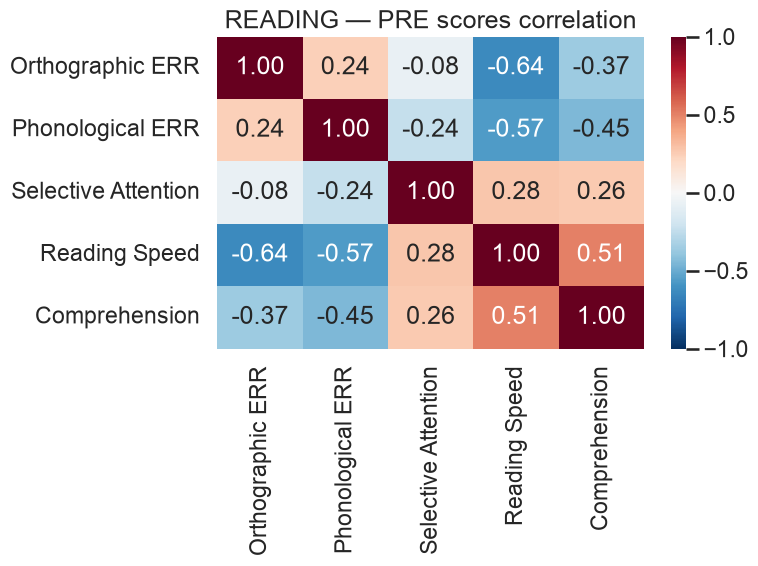

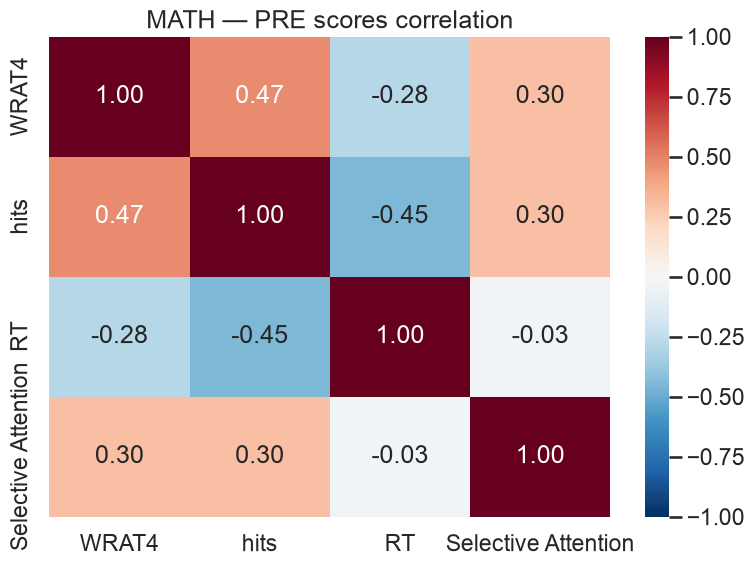

In [82]:
for name, df, dvs in [("reading", df_reading, reading_dvs), ("math", df_math, math_dvs)]:
    corr_cols = [f"{dv}_PRE" for dv in dvs]
    fig, ax = plt.subplots(figsize=(8, 6))
    corr = df[corr_cols].corr()
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r",
                center=0, vmin=-1, vmax=1, ax=ax,
                xticklabels=[c.replace("_PRE", "").replace("_", " ") for c in corr_cols],
                yticklabels=[c.replace("_PRE", "").replace("_", " ") for c in corr_cols])
    ax.set_title(f"{name.upper()} \u2014 PRE scores correlation")
    fig.tight_layout()
    fig.savefig(OUT / f"corr_{name}_pre.png", dpi=150, bbox_inches="tight")
    plt.show()

### Correlation Heatmaps (Change scores)

Correlations between the change scores (POST − PRE) of each DV pair.

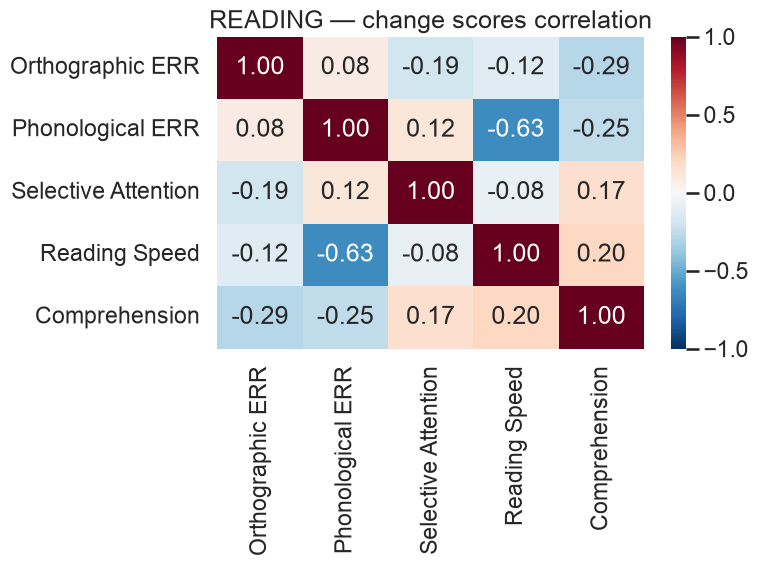

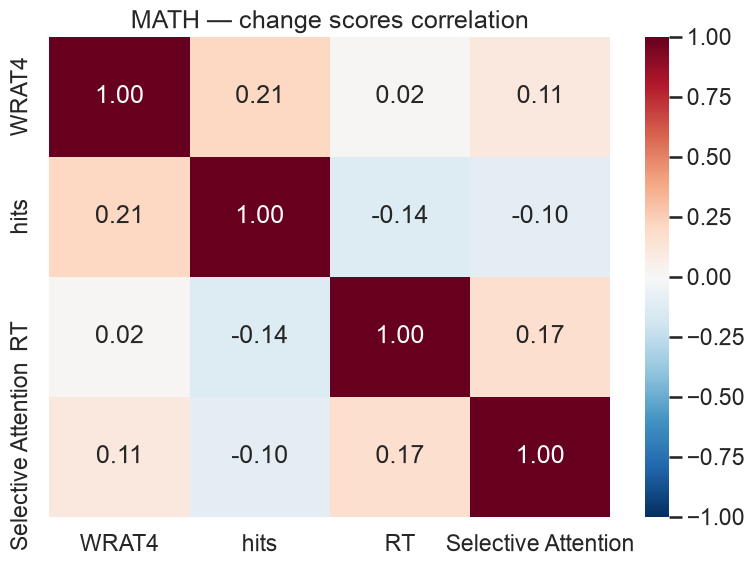

In [83]:
for name, df, dvs in [("reading", df_reading, reading_dvs), ("math", df_math, math_dvs)]:
    change_cols = [f"{dv}_CHG" for dv in dvs]
    d = df.copy()
    for dv in dvs:
        d[f"{dv}_CHG"] = d[f"{dv}_POST"] - d[f"{dv}_PRE"]
    corr = d[change_cols].corr()
    fig, ax = plt.subplots(figsize=(8, 6))
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r",
                center=0, vmin=-1, vmax=1, ax=ax,
                xticklabels=[c.replace("_CHG", "").replace("_", " ") for c in change_cols],
                yticklabels=[c.replace("_CHG", "").replace("_", " ") for c in change_cols])
    ax.set_title(f"{name.upper()} \u2014 change scores correlation")
    fig.tight_layout()
    fig.savefig(OUT / f"corr_{name}_change.png", dpi=150, bbox_inches="tight")
    plt.show()

### Age / IQ vs PRE DVs

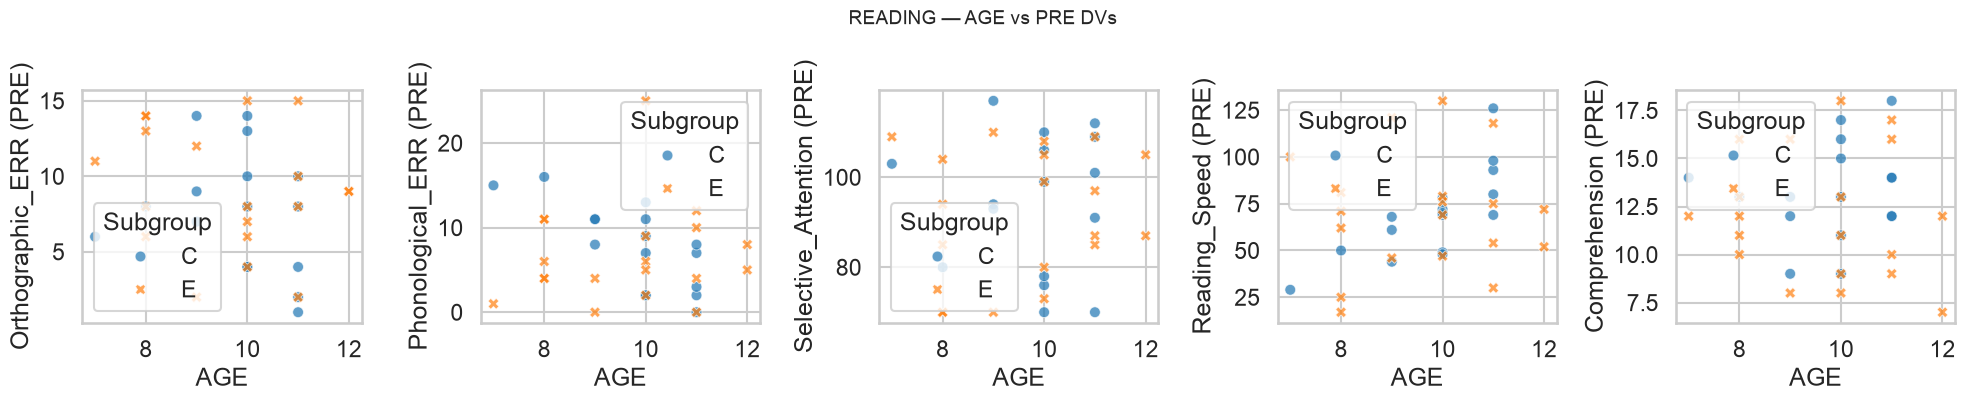

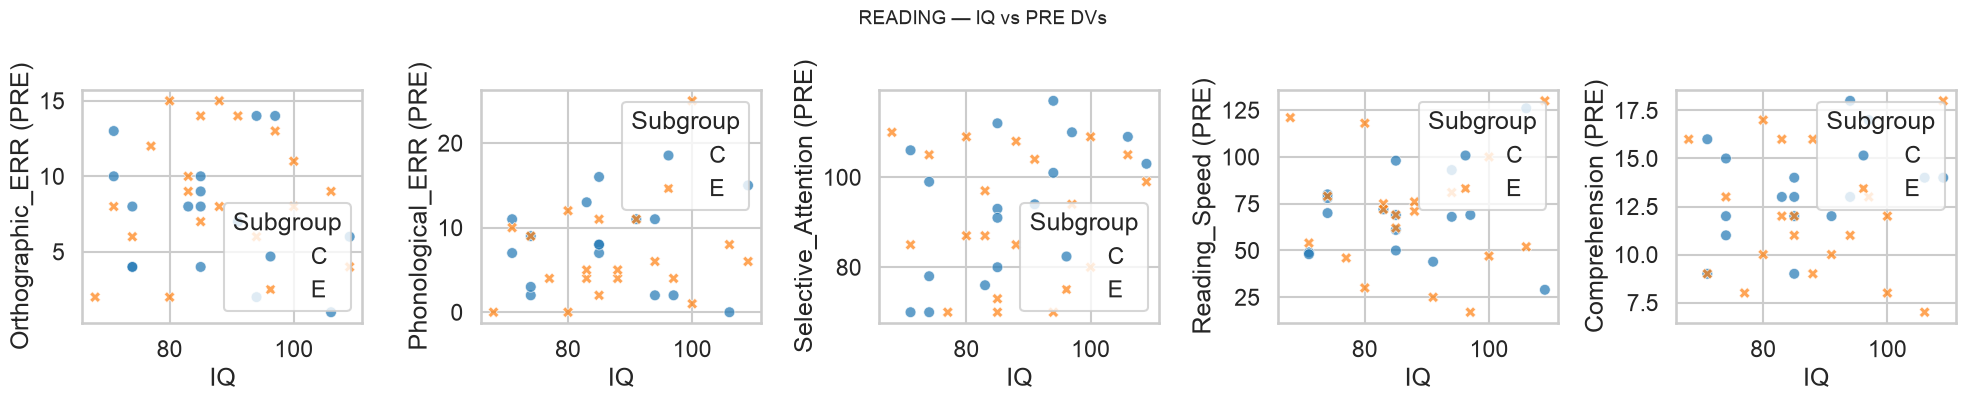

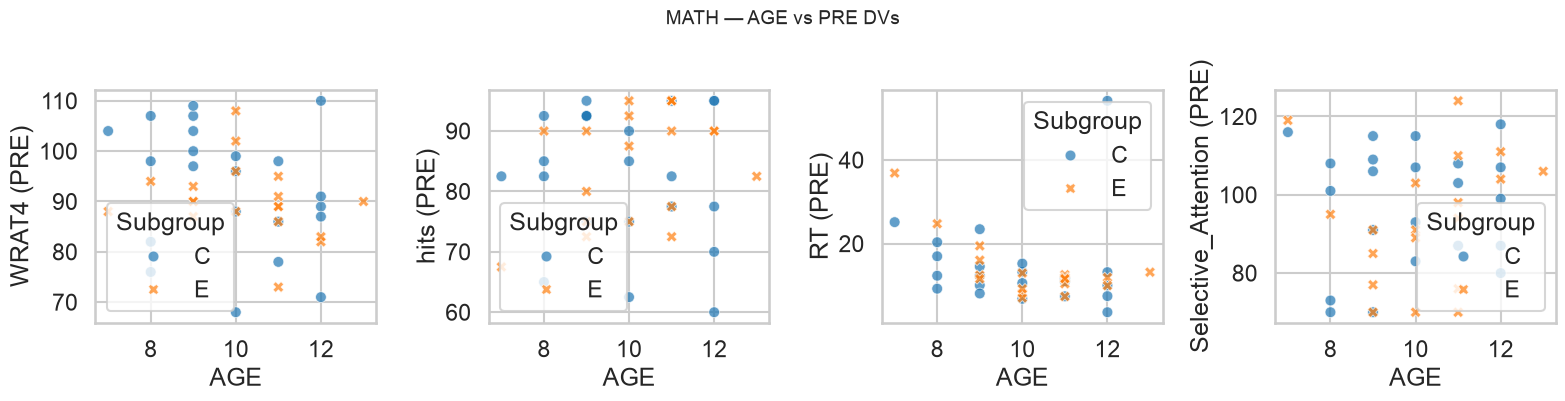

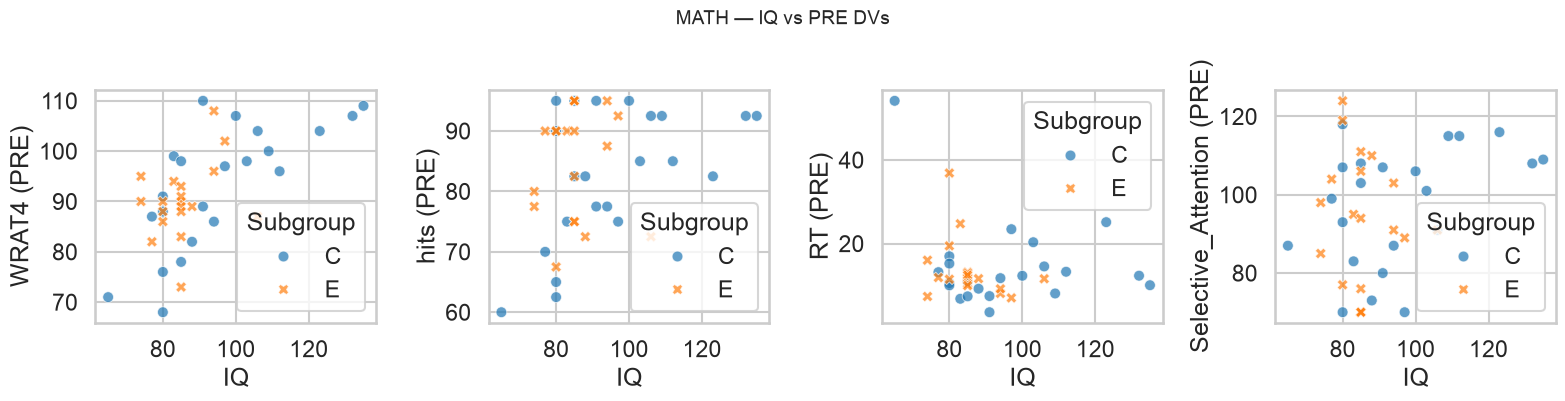

In [84]:
for name, df, dvs in [("reading", df_reading, reading_dvs), ("math", df_math, math_dvs)]:
    for cov in ["AGE", "IQ"]:
        n_dvs = len(dvs)
        fig, axes = plt.subplots(1, n_dvs, figsize=(4 * n_dvs, 4), sharey=False)
        if n_dvs == 1:
            axes = [axes]
        for j, dv in enumerate(dvs):
            ax = axes[j]
            sns.scatterplot(data=df, x=cov, y=f"{dv}_PRE", hue="Subgroup",
                style="Subgroup", s=60, ax=ax, alpha=0.7)
            ax.set_ylabel(f"{dv} (PRE)")
            ax.set_xlabel(cov)
        fig.suptitle(f"{name.upper()} \u2014 {cov} vs PRE DVs", fontsize=14, y=1.02)
        fig.tight_layout()
        fig.savefig(OUT / f"scatter_{name}_{cov.lower()}_pre.png", dpi=150, bbox_inches="tight")
        plt.show()

### Effect of IQ & Gender on Change

- **IQ vs change**: Spearman, per subgroup (C | E).
- **Gender effect**: Mann–Whitney F vs M, per subgroup.
- **Treatment × Gender**: E vs C within each gender, plus OLS interaction (Change ~ Group + Gender + Group:Gender).

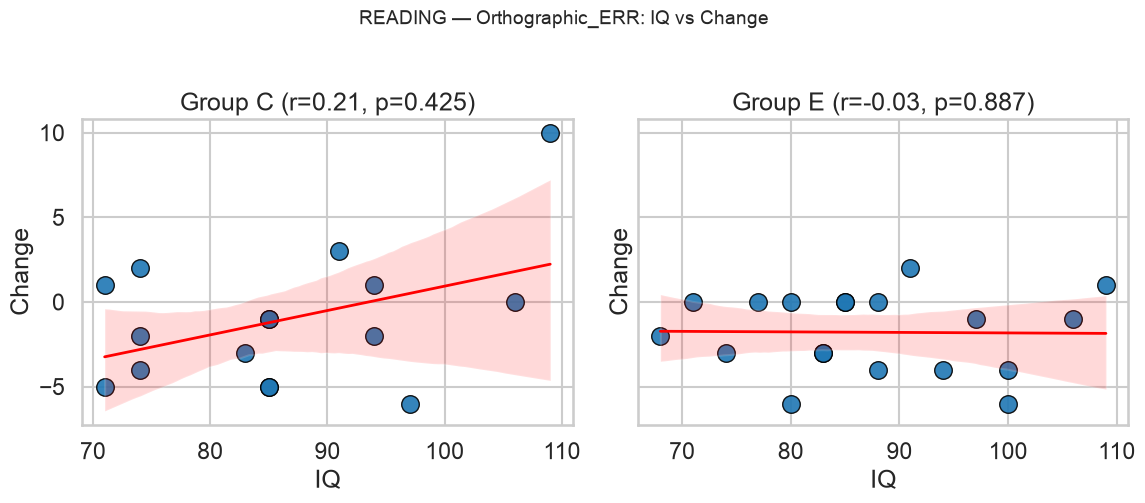

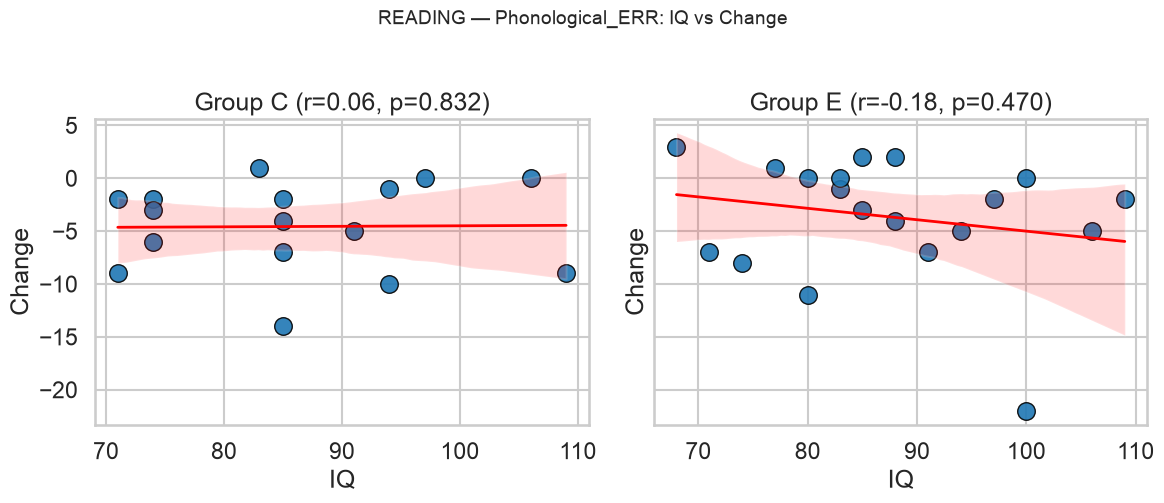

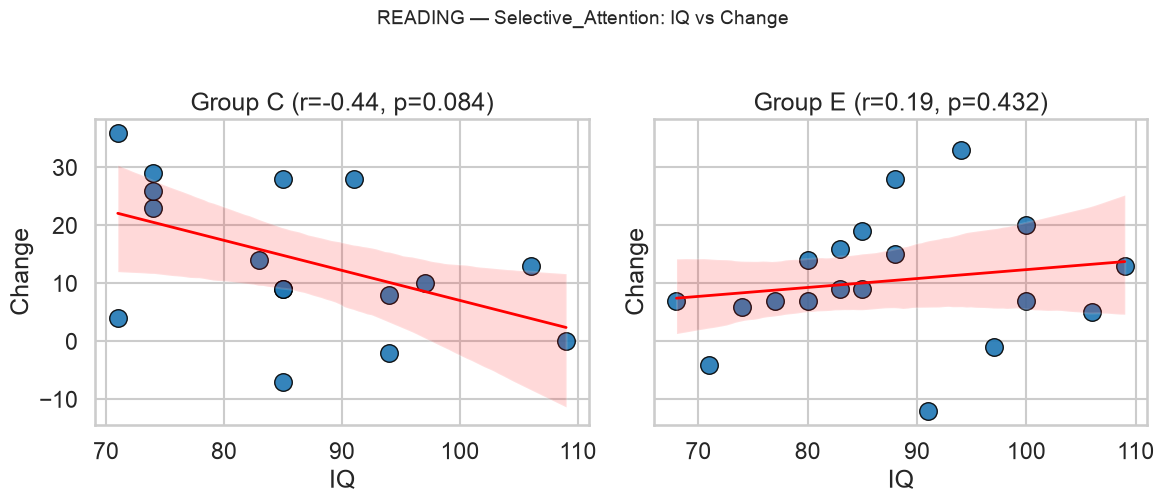

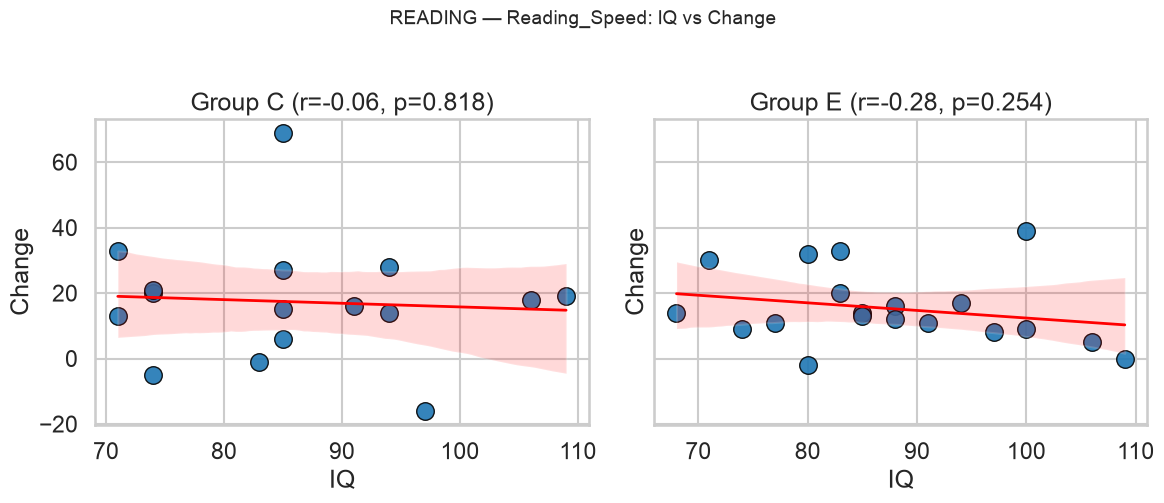

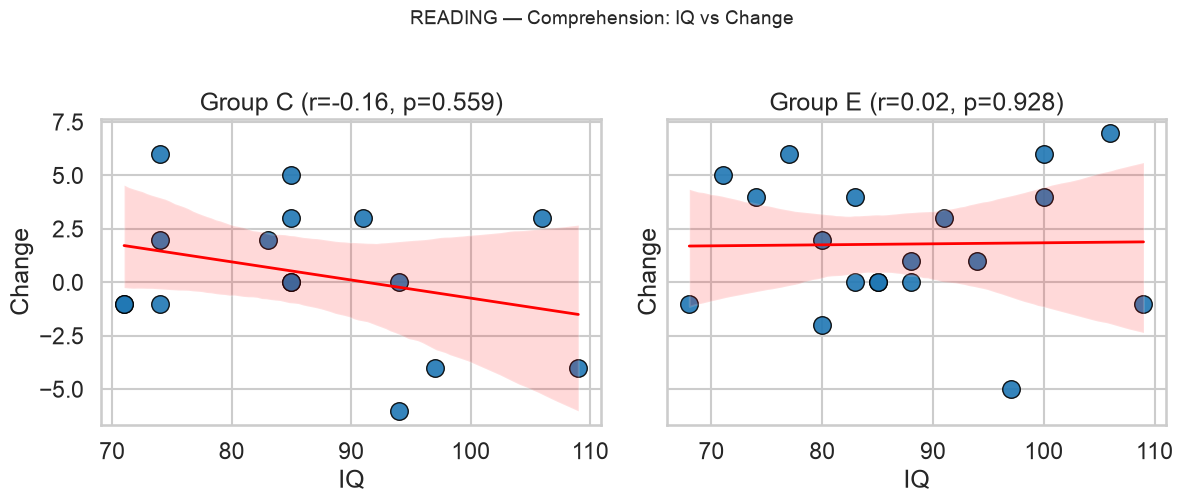

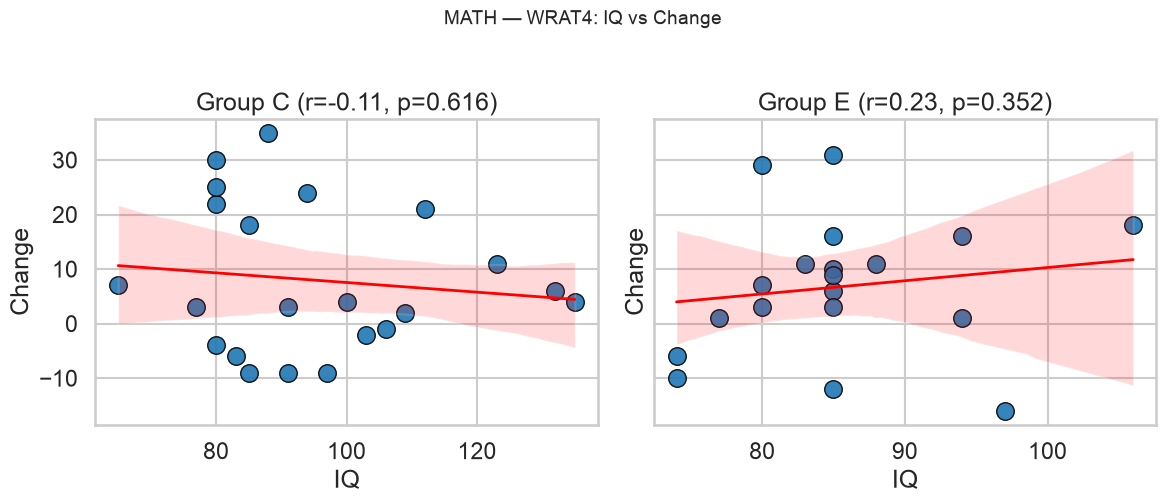

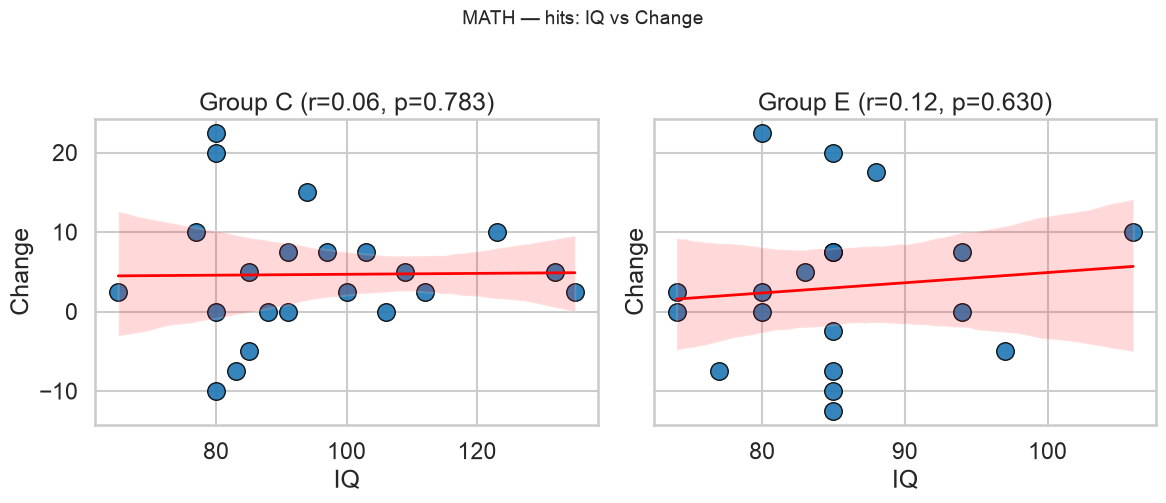

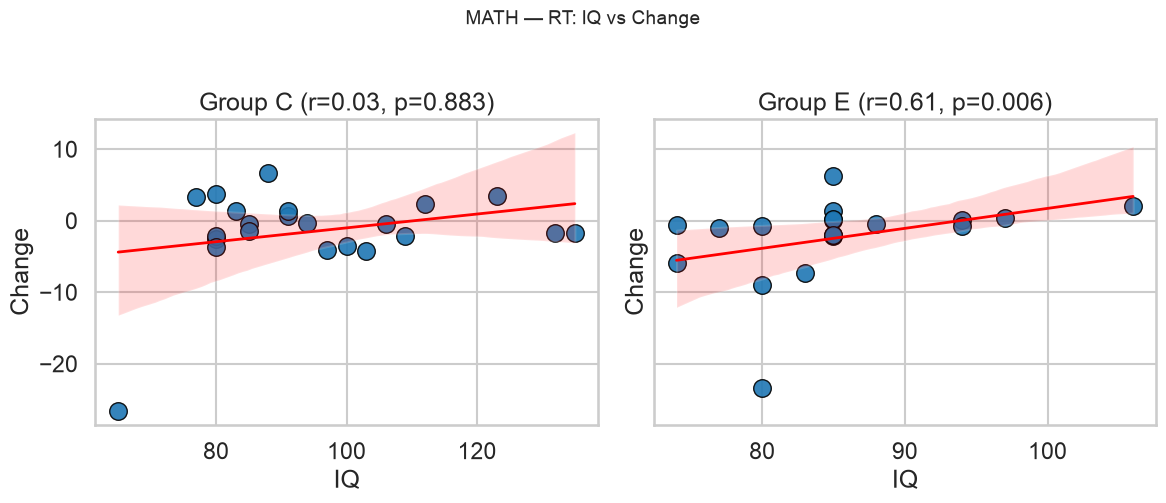

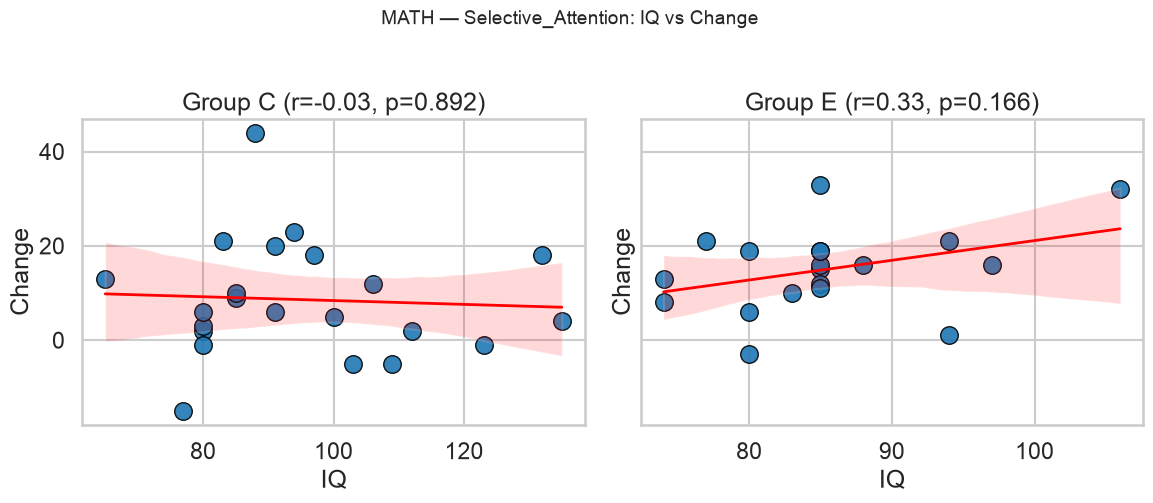

In [85]:
for name, df, dvs in [("reading", df_reading, reading_dvs), ("math", df_math, math_dvs)]:
    rows = []
    for dv in dvs:
        tmp = df[["Subject", "Subgroup", "IQ", f"{dv}_PRE", f"{dv}_POST"]].copy()
        tmp["Change"] = tmp[f"{dv}_POST"] - tmp[f"{dv}_PRE"]
        tmp = tmp.dropna(subset=["Change", "IQ"])
        fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
        for i, grp in enumerate(["C", "E"]):
            ax = axes[i]
            sub = tmp[tmp.Subgroup == grp]
            rho, p = stats.spearmanr(sub["IQ"], sub["Change"])
            rows.append({"DV": dv, "Subgroup": grp, "Spearman_r": rho, "p": p, "n": len(sub)})
            sns.regplot(data=sub, x="IQ", y="Change", ax=ax,
                        scatter_kws={"s": 160, "alpha": 0.9,
                                     "edgecolor": "black"},
                        line_kws={"color": "red", "linewidth": 2})
            ax.set_title(f"Group {grp} (r={rho:.2f}, p={p:.3f})")
            ax.set_xlabel("IQ")
        fig.suptitle(f"{name.upper()} \u2014 {dv}: IQ vs Change", fontsize=14, y=1.02)
        fig.tight_layout()
        fig.savefig(OUT / f"scatter_{name}_iq_change_{dv}.png", dpi=150, bbox_inches="tight")
        plt.show()
    res = pd.DataFrame(rows)
    res = res.round(4)
    res.to_csv(OUT / f"iq_change_corr_{name}.csv", index=False)
    res

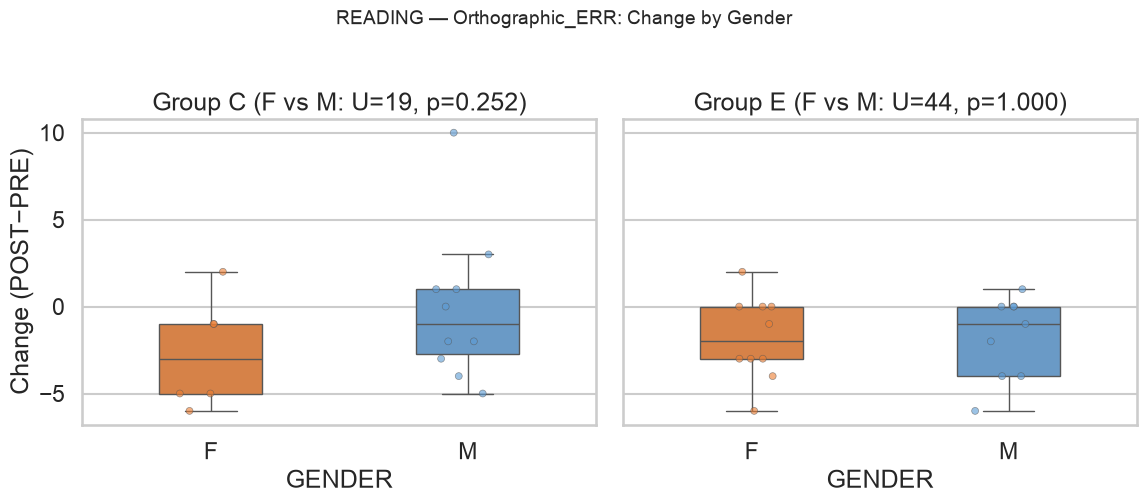

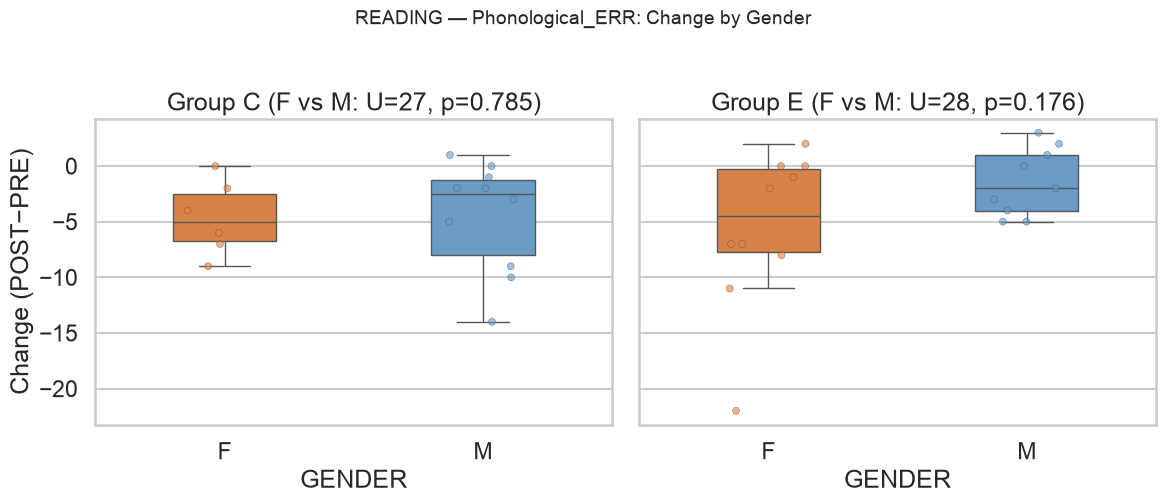

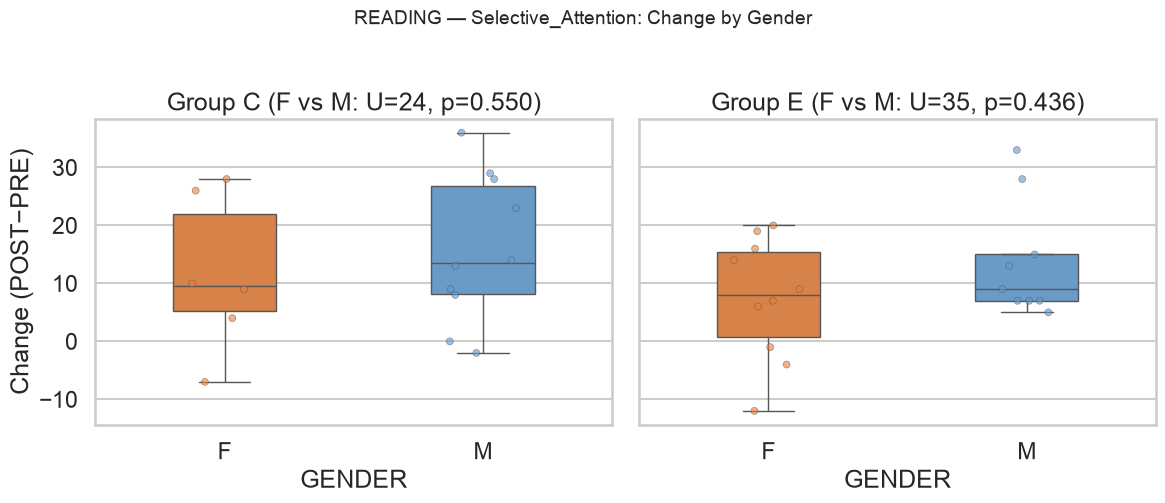

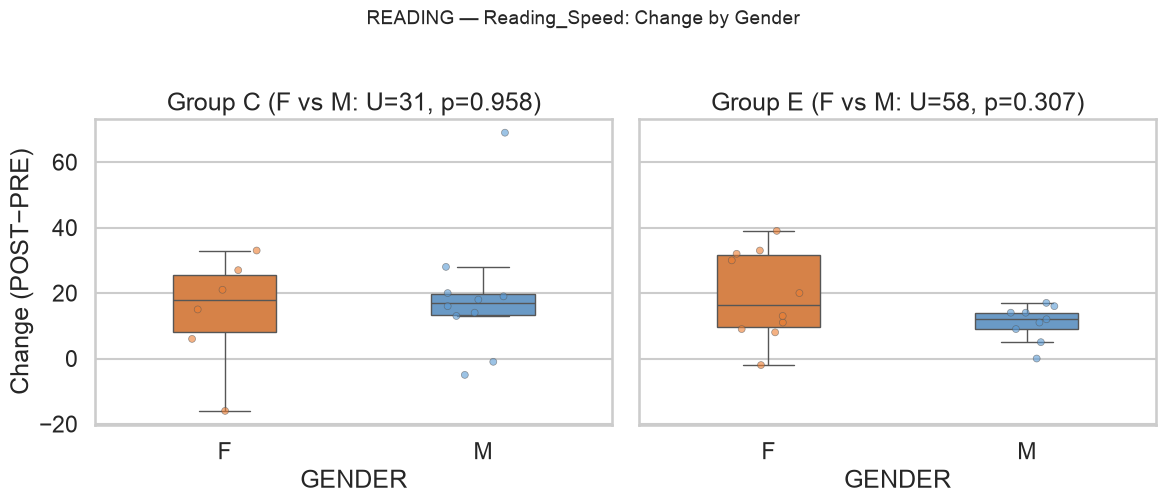

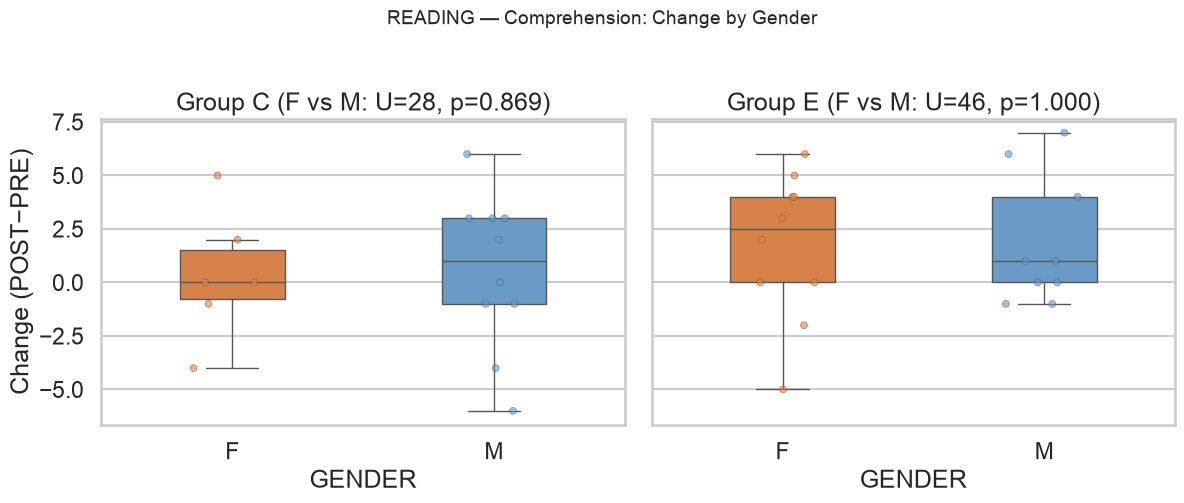

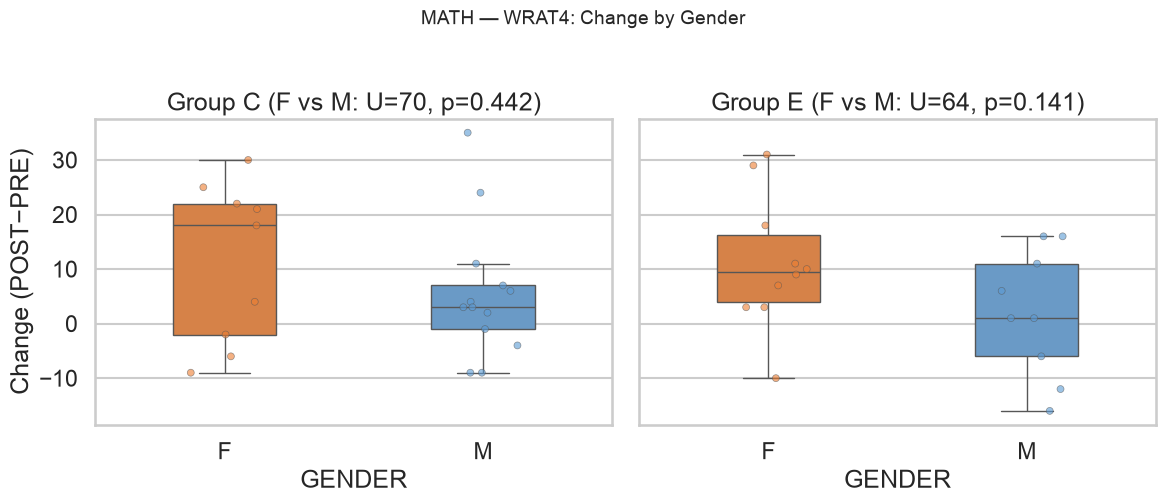

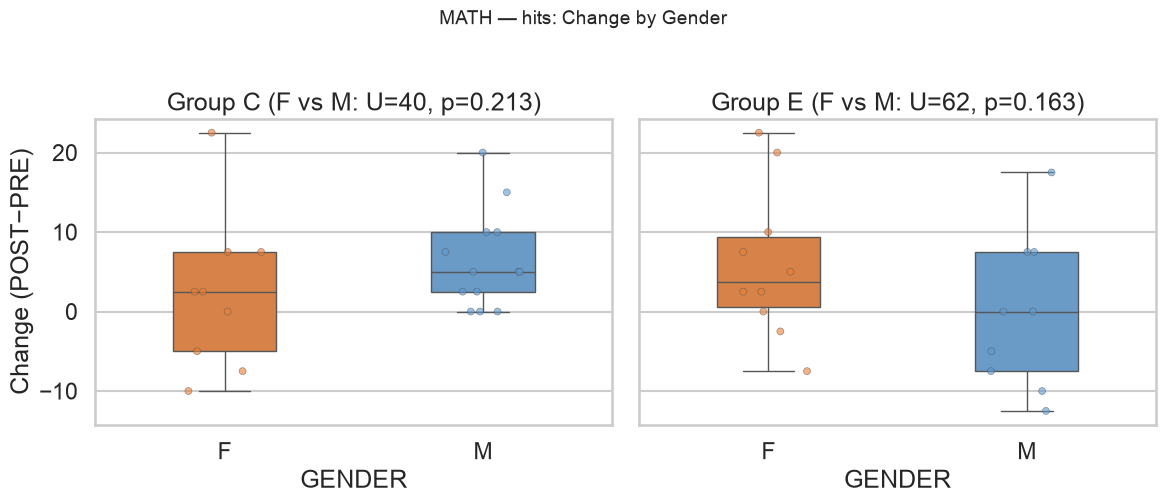

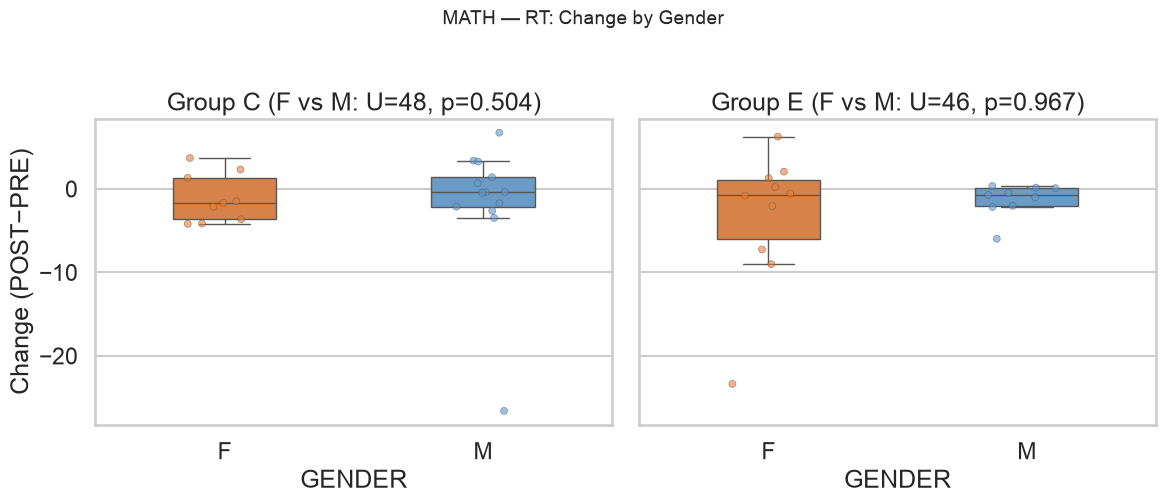

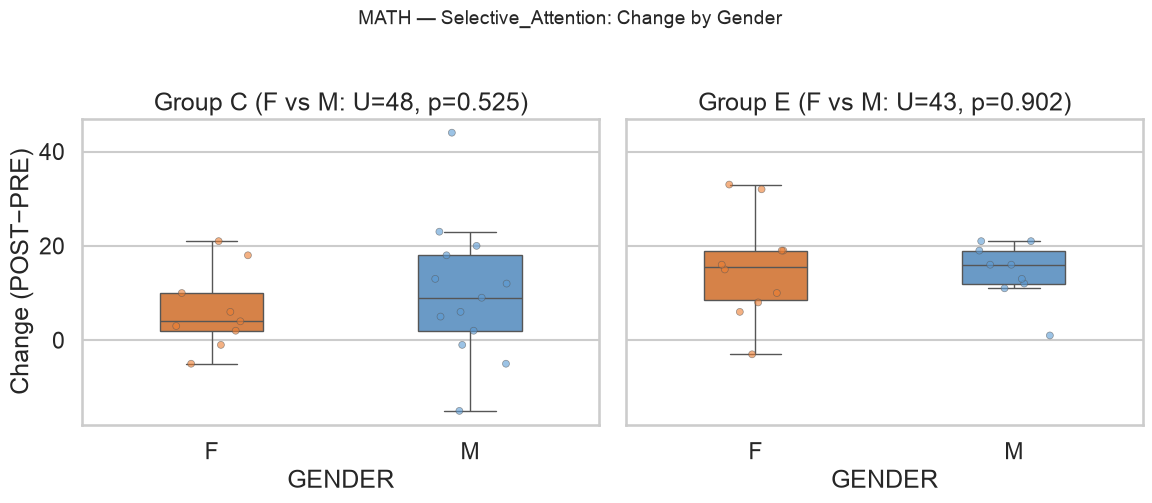

In [86]:
for name, df, dvs in [("reading", df_reading, reading_dvs), ("math", df_math, math_dvs)]:
    rows = []
    for dv in dvs:
        tmp = df[["Subject", "Subgroup", "GENDER", f"{dv}_PRE", f"{dv}_POST"]].copy()
        tmp["Change"] = tmp[f"{dv}_POST"] - tmp[f"{dv}_PRE"]
        tmp = tmp.dropna(subset=["Change"])
        fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
        for i, grp in enumerate(["C", "E"]):
            ax = axes[i]
            sub = tmp[tmp.Subgroup == grp]
            fvals = sub.loc[sub.GENDER == "F", "Change"]
            mvals = sub.loc[sub.GENDER == "M", "Change"]
            U, p = stats.mannwhitneyu(fvals, mvals, alternative="two-sided")
            rows.append({"DV": dv, "Subgroup": grp, "Mean_F": fvals.mean(),
                         "Mean_M": mvals.mean(), "U": U, "p": p,
                         "n_F": len(fvals), "n_M": len(mvals)})
            sns.boxplot(data=sub, x="GENDER", y="Change", order=["F", "M"], ax=ax,
                        palette={"F": "#ED7D31", "M": "#5B9BD5"}, width=0.4, fliersize=0)
            sns.stripplot(data=sub, x="GENDER", y="Change", order=["F", "M"], ax=ax,
                          palette={"F": "#ED7D31", "M": "#5B9BD5"},
                          size=5, alpha=0.6, jitter=0.15, edgecolor="gray", linewidth=0.5)
            ax.set_title(f"Group {grp} (F vs M: U={U:.0f}, p={p:.3f})")
            ax.set_ylabel("Change (POST\u2212PRE)")
        fig.suptitle(f"{name.upper()} \u2014 {dv}: Change by Gender", fontsize=14, y=1.02)
        fig.tight_layout()
        fig.savefig(OUT / f"gender_change_{name}_{dv}.png", dpi=150, bbox_inches="tight")
        plt.show()
    res = pd.DataFrame(rows)
    res = res.round(4)
    res.to_csv(OUT / f"gender_change_{name}.csv", index=False)
    res

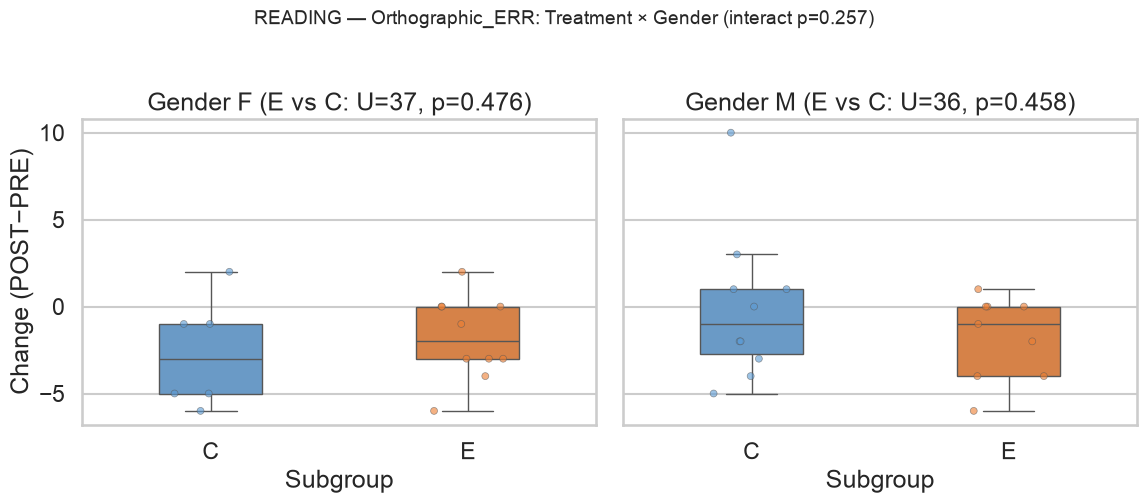

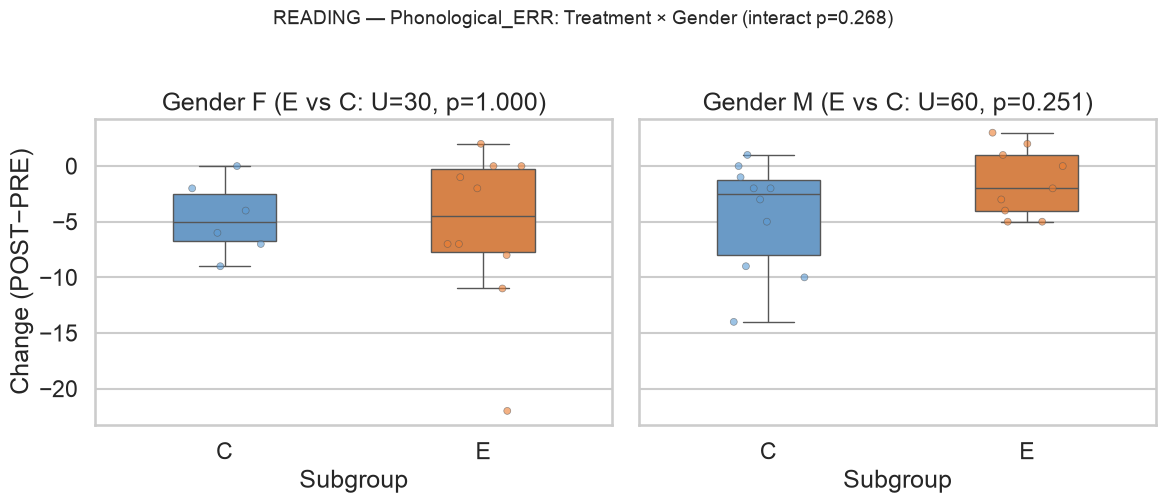

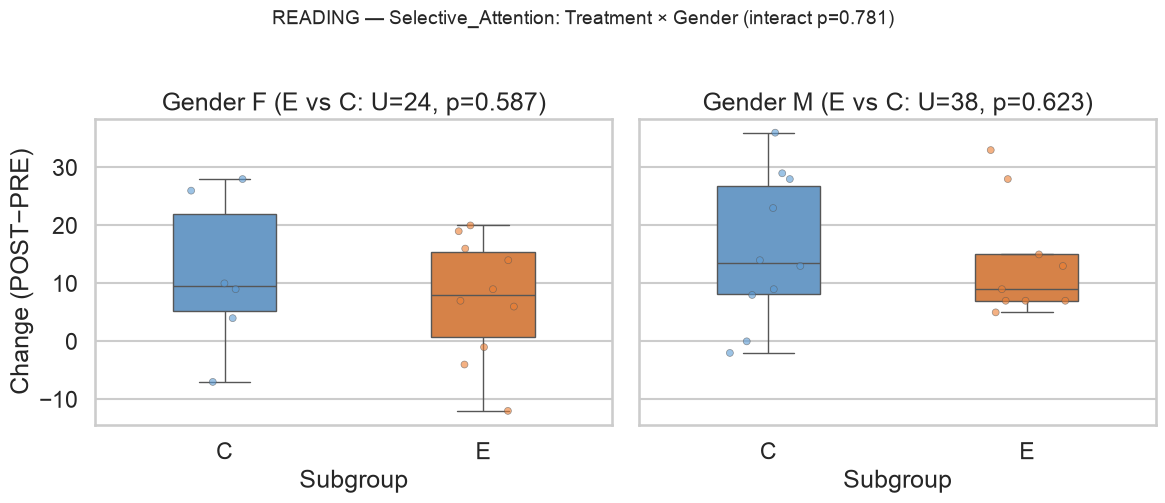

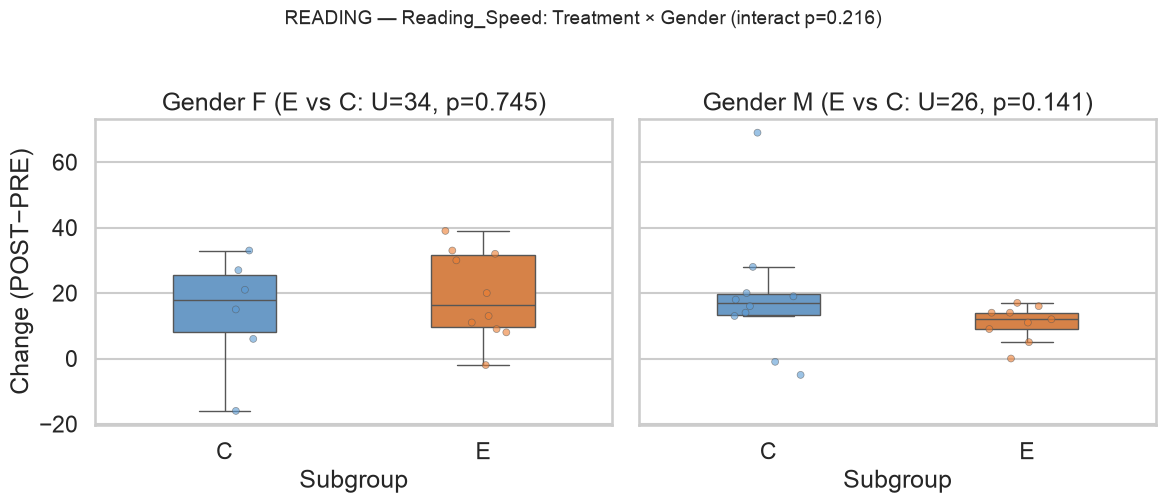

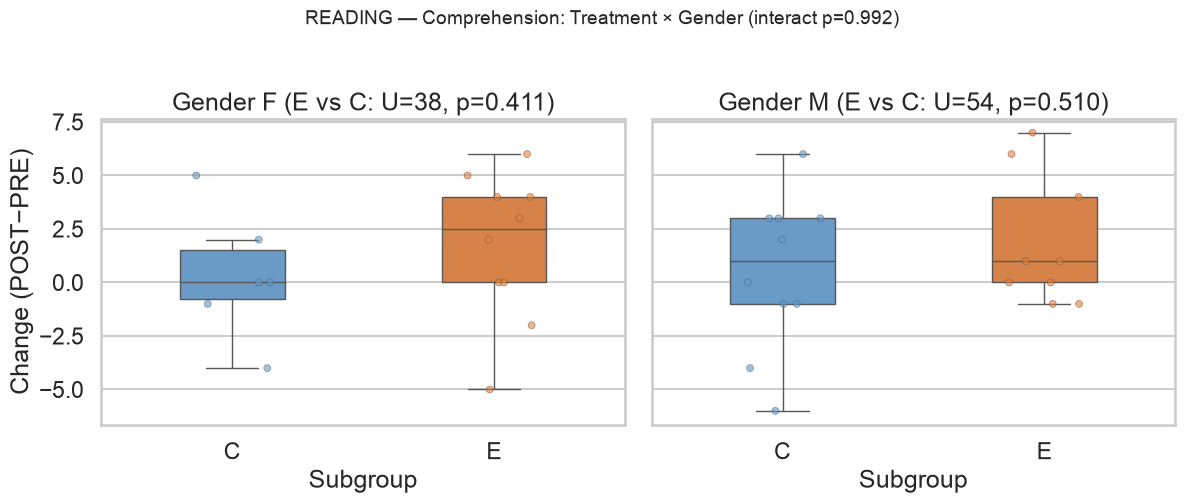

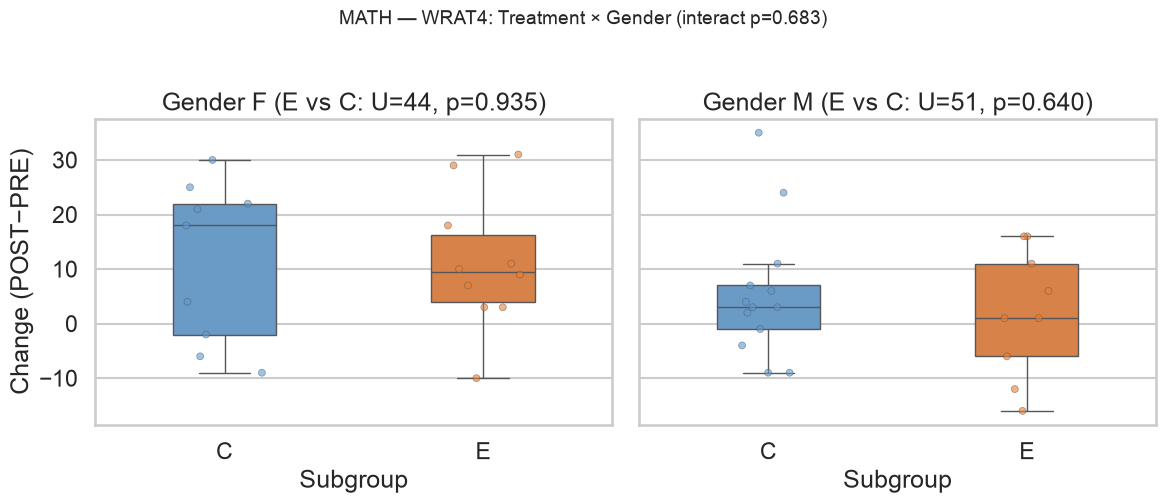

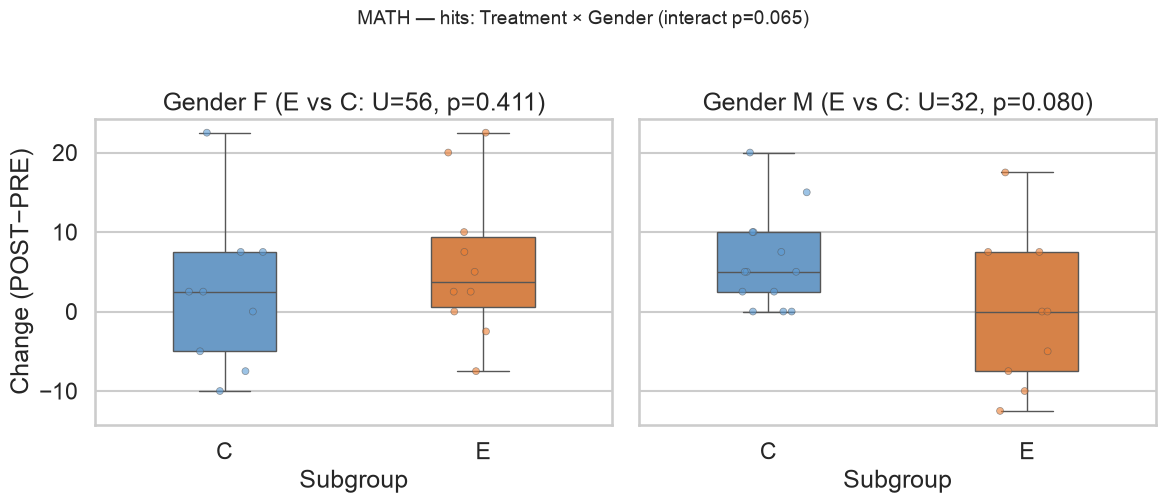

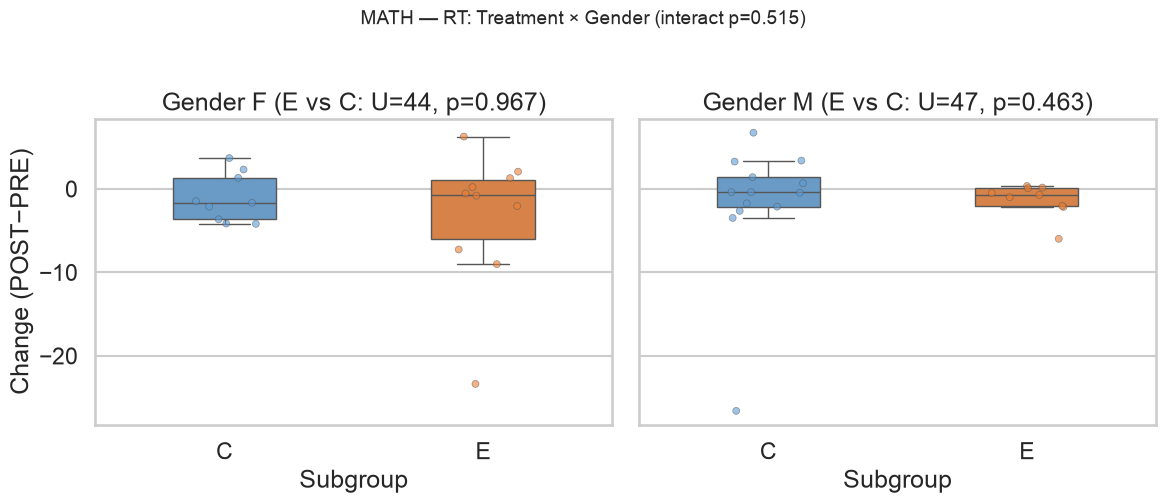

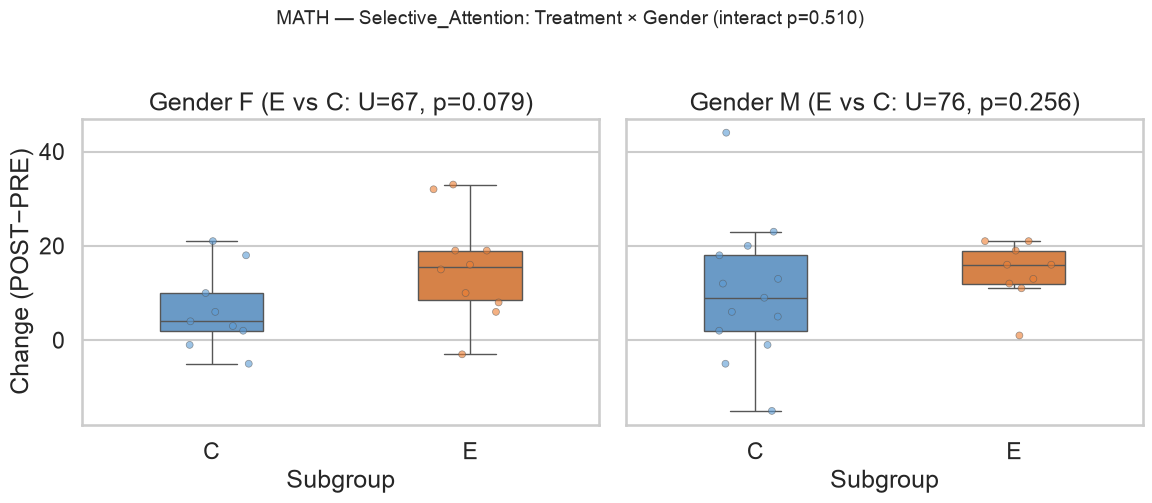

In [87]:
import statsmodels.api as sm

for name, df, dvs in [("reading", df_reading, reading_dvs), ("math", df_math, math_dvs)]:
    rows = []
    for dv in dvs:
        tmp = df[["Subject", "Subgroup", "GENDER", f"{dv}_PRE", f"{dv}_POST"]].copy()
        tmp["Change"] = tmp[f"{dv}_POST"] - tmp[f"{dv}_PRE"]
        tmp = tmp.dropna(subset=["Change"])
        tmp["is_E"] = (tmp.Subgroup == "E").astype(int)
        tmp["is_M"] = (tmp.GENDER == "M").astype(int)
        X = pd.DataFrame({"const": 1, "is_E": tmp["is_E"], "is_M": tmp["is_M"],
                          "E_x_M": tmp["is_E"] * tmp["is_M"]})
        ols = sm.OLS(tmp["Change"], X).fit()

        fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
        for i, g in enumerate(["F", "M"]):
            ax = axes[i]
            sub = tmp[tmp.GENDER == g]
            evals = sub.loc[sub.Subgroup == "E", "Change"]
            cvals = sub.loc[sub.Subgroup == "C", "Change"]
            U, p = stats.mannwhitneyu(evals, cvals, alternative="two-sided")
            sns.boxplot(data=sub, x="Subgroup", y="Change", order=["C", "E"], ax=ax,
                        palette={"C": "#5B9BD5", "E": "#ED7D31"}, width=0.4, fliersize=0)
            sns.stripplot(data=sub, x="Subgroup", y="Change", order=["C", "E"], ax=ax,
                          palette={"C": "#5B9BD5", "E": "#ED7D31"},
                          size=5, alpha=0.6, jitter=0.15, edgecolor="gray", linewidth=0.5)
            ax.set_title(f"Gender {g} (E vs C: U={U:.0f}, p={p:.3f})")
            ax.set_ylabel("Change (POST\u2212PRE)")
        fig.suptitle(f"{name.upper()} \u2014 {dv}: Treatment \u00d7 Gender "
                     f"(interact p={ols.pvalues['E_x_M']:.3f})", fontsize=14, y=1.02)
        fig.tight_layout()
        fig.savefig(OUT / f"gender_treatment_{name}_{dv}.png", dpi=150, bbox_inches="tight")
        plt.show()

        rows.append({"DV": dv, "b_E": ols.params["is_E"], "p_E": ols.pvalues["is_E"],
                     "b_Male": ols.params["is_M"], "p_Male": ols.pvalues["is_M"],
                     "b_E_x_M": ols.params["E_x_M"], "p_E_x_M": ols.pvalues["E_x_M"]})
    res = pd.DataFrame(rows)
    res = res.round(4)
    res.to_csv(OUT / f"gender_treatment_{name}.csv", index=False)
    res[["DV", "p_E", "p_Male", "b_E_x_M", "p_E_x_M"]]

---
## 3. EEG Data Availability

In [88]:
xl = pd.ExcelFile(ROOT / "02_EEG_Data_Descriptor.xlsx")

# --- Parse Reading availability ---
df_raw = xl.parse("Reading_Data_Available", header=None)
df_r = df_raw.iloc[2:, :6].copy()  # PRE columns
df_r.columns = ["Subject", "Subgroup", "Psychometry", "EEG_Baseline", "EEG_Reading", "Complete"]
df_r_post = df_raw.iloc[2:, [0, 7, 8, 9, 10]].copy()
df_r_post.columns = ["Subject", "Psychometry_POST", "EEG_Baseline_POST", "EEG_Reading_POST", "Complete_POST"]
df_r_all = df_r.merge(df_r_post, on="Subject")
df_r_all.to_csv(OUT / "eeg_availability_reading.csv", index=False)

# --- Parse Math availability ---
df_mu = xl.parse("Math_Data_Available", header=None)
df_m = df_mu.iloc[2:, :7].copy()
df_m.columns = ["Subject", "Subgroup", "Psychometry", "EEG_Baseline", "EEG_B1", "EEG_B2", "Complete"]
df_m_post = df_mu.iloc[2:, [0, 8, 9, 10, 11, 12]].copy()
df_m_post.columns = ["Subject", "Psychometry_POST", "EEG_Baseline_POST", "EEG_B1_POST", "EEG_B2_POST", "Complete_POST"]
df_m_all = df_m.merge(df_m_post, on="Subject")
df_m_all.to_csv(OUT / "eeg_availability_math.csv", index=False)

print(f"Reading EEG: {len(df_r_all)} subjects")
print(f"Math EEG: {len(df_m_all)} subjects")

Reading EEG: 38 subjects
Math EEG: 44 subjects


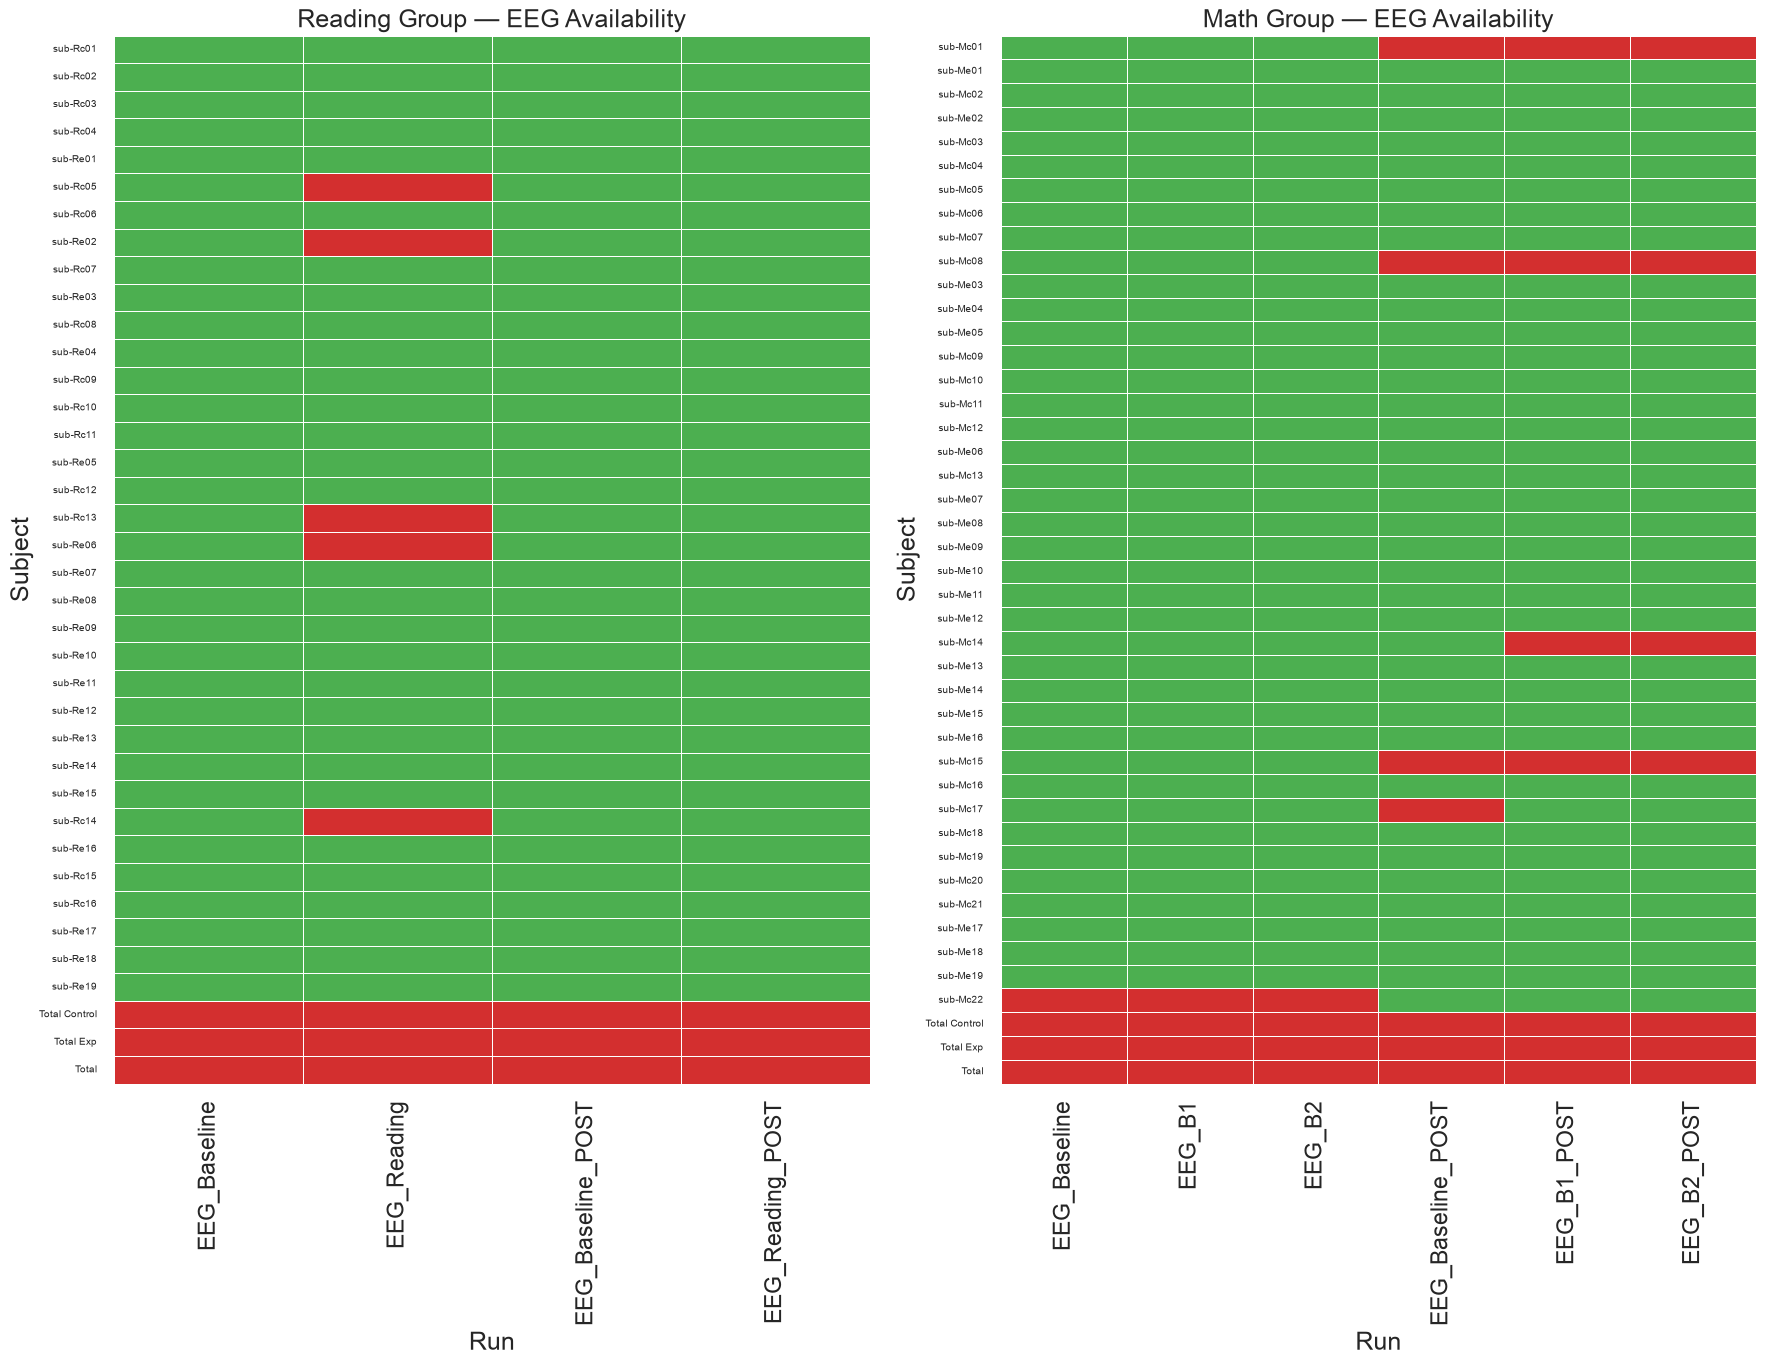


Reading — missing/corrupted by run:
EEG_Baseline         3
EEG_Reading          8
EEG_Baseline_POST    3
EEG_Reading_POST     3
dtype: int64

Math — missing/corrupted by run:
EEG_Baseline         4
EEG_B1               4
EEG_B2               4
EEG_Baseline_POST    7
EEG_B1_POST          7
EEG_B2_POST          7
dtype: int64


In [89]:
# Build YES/NO matrix for heatmap
def build_avail_matrix(df_all, run_cols):
    """Binary matrix: 1 = data available, 0 = missing/corrupted."""
    subj = df_all["Subject"]
    matrix = []
    for _, row in df_all.iterrows():
        vals = []
        for c in run_cols:
            v = str(row[c]).strip().upper()
            vals.append(1 if v == "YES" else 0)
        matrix.append(vals)
    return pd.DataFrame(matrix, index=subj, columns=run_cols)

fig, axes = plt.subplots(1, 2, figsize=(18, 14))

reading_cols = ["EEG_Baseline", "EEG_Reading", "EEG_Baseline_POST", "EEG_Reading_POST"]
mat_r = build_avail_matrix(df_r_all, reading_cols)
sns.heatmap(mat_r, cmap=["#D32F2F", "#4CAF50"], linewidths=0.5, ax=axes[0],
            cbar=False, yticklabels=True)
axes[0].set_title("Reading Group — EEG Availability")
axes[0].set_xlabel("Run")
axes[0].tick_params(axis="y", labelsize=7)

math_cols = ["EEG_Baseline", "EEG_B1", "EEG_B2", "EEG_Baseline_POST", "EEG_B1_POST", "EEG_B2_POST"]
mat_m = build_avail_matrix(df_m_all, math_cols)
sns.heatmap(mat_m, cmap=["#D32F2F", "#4CAF50"], linewidths=0.5, ax=axes[1],
            cbar=False, yticklabels=True)
axes[1].set_title("Math Group — EEG Availability")
axes[1].set_xlabel("Run")
axes[1].tick_params(axis="y", labelsize=7)

fig.tight_layout()
fig.savefig(OUT / "eeg_availability_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

# Summary counts
print("\nReading — missing/corrupted by run:")
print((mat_r == 0).sum())
print(f"\nMath — missing/corrupted by run:")
print((mat_m == 0).sum())

---
## 4. Session Engagement

In [90]:
eng = pd.read_excel(ROOT / "05_SessionEngagement.xlsx")
eng = eng[["Subject", "Smartick program", "Session Engagement (%)"]].copy()
eng.columns = ["Subject", "Program", "Engagement"]

print(f"N = {len(eng)}")
print(f"Programs: {eng.Program.value_counts().to_dict()}")
print(f"\nEngagement overall:")
print(eng.Engagement.describe().to_string())
print(f"\nBy program:")
print(eng.groupby("Program")["Engagement"].describe().round(4).to_string())

N = 38
Programs: {'Reading': 19, 'Math': 19}

Engagement overall:
count    38.000000
mean      0.765786
std       0.235638
min       0.398305
25%       0.609375
50%       0.700769
75%       0.880000
max       1.333333

By program:
         count    mean     std     min     25%   50%     75%     max
Program                                                             
Math      19.0  0.6957  0.1827  0.3983  0.5625  0.66  0.8486  1.1238
Reading   19.0  0.8359  0.2653  0.5357  0.6484  0.72  1.0068  1.3333


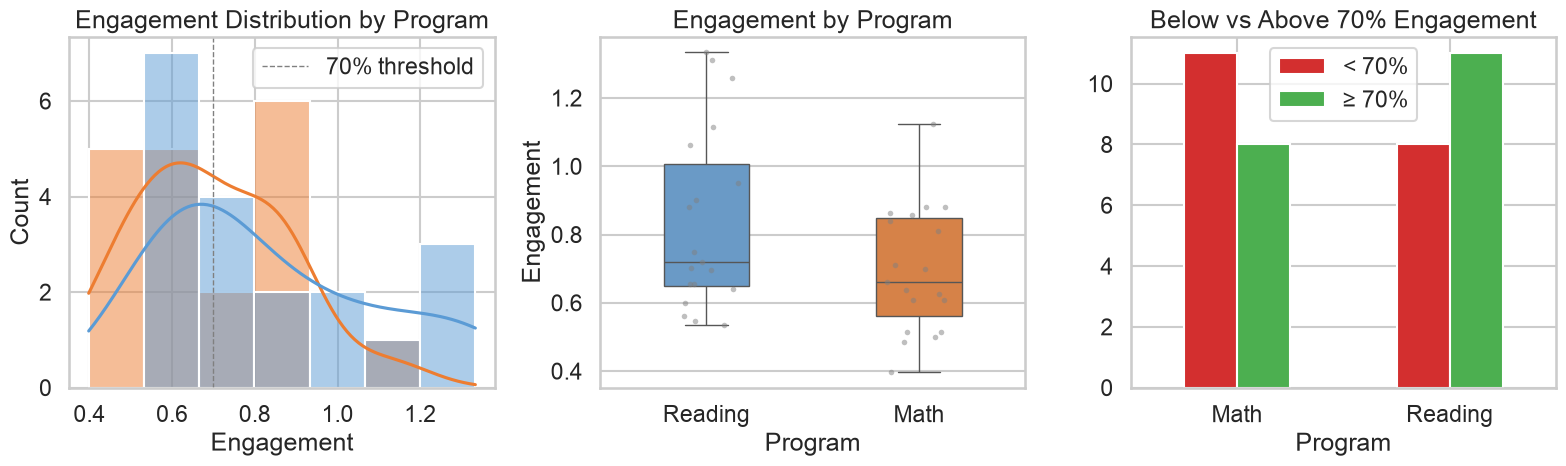

In [91]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Distribution by program
sns.histplot(data=eng, x="Engagement", hue="Program", kde=True, ax=axes[0],
             palette={"Reading": "#5B9BD5", "Math": "#ED7D31"}, edgecolor="white")
axes[0].axvline(0.70, color="gray", ls="--", lw=1, label="70% threshold")
axes[0].legend()
axes[0].set_title("Engagement Distribution by Program")

# Boxplot by program
sns.boxplot(data=eng, x="Program", y="Engagement", ax=axes[1],
            palette={"Reading": "#5B9BD5", "Math": "#ED7D31"}, width=0.4)
sns.stripplot(data=eng, x="Program", y="Engagement", ax=axes[1],
              color="gray", alpha=0.5, size=4, jitter=0.15)
axes[1].set_title("Engagement by Program")

# Below vs above 70%
eng["HighEngagement"] = eng["Engagement"] >= 0.70
ct = pd.crosstab(eng["Program"], eng["HighEngagement"])
ct.plot(kind="bar", ax=axes[2], color=["#D32F2F", "#4CAF50"])
axes[2].set_title("Below vs Above 70% Engagement")
axes[2].set_xlabel("Program")
axes[2].tick_params(axis="x", rotation=0)
axes[2].legend(["< 70%", "\u2265 70%"])

fig.tight_layout()
fig.savefig(OUT / "engagement_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

---
## 5. Event Tags Structure

In [92]:
rt = pd.read_excel(ROOT / "03_Reading_Tags.xlsx")
mt = pd.read_excel(ROOT / "04_Math_Tags.xlsx")

print(f"Reading tags: {len(rt)} events, {rt.Subject.nunique()} subjects")
print(f"  Groups: {rt.Group.value_counts().to_dict()}")
print(f"  Interventions: {rt.Intervention.value_counts().to_dict()}")
print(f"  Descriptions: {rt.Description.value_counts().to_dict()}")

print(f"\nMath tags: {len(mt)} events, {mt.Subject.nunique()} subjects")
print(f"  Groups: {mt.Group.value_counts().to_dict()}")
print(f"  Interventions: {mt.Intervention.value_counts().to_dict()}")
print(f"  Blocks: {mt.Block.value_counts().to_dict()}")

Reading tags: 414 events, 34 subjects
  Groups: {'Experimental': 222, 'Control': 192}
  Interventions: {'POST': 264, 'PRE': 150}
  Descriptions: {'Answer 1': 72, 'Start reading': 65, 'End reading': 63, 'Answer 2': 63, 'Answer 3': 50, 'Question 1': 33, 'Question 2': 33, 'Question 3': 33, 'Irrelevant': 2}

Math tags: 5202 events, 40 subjects
  Groups: {'Control': 2666, 'Experimental': 2536}
  Interventions: {'PRE': 2642, 'POST': 2560}
  Blocks: {2: 2666, 1: 2536}


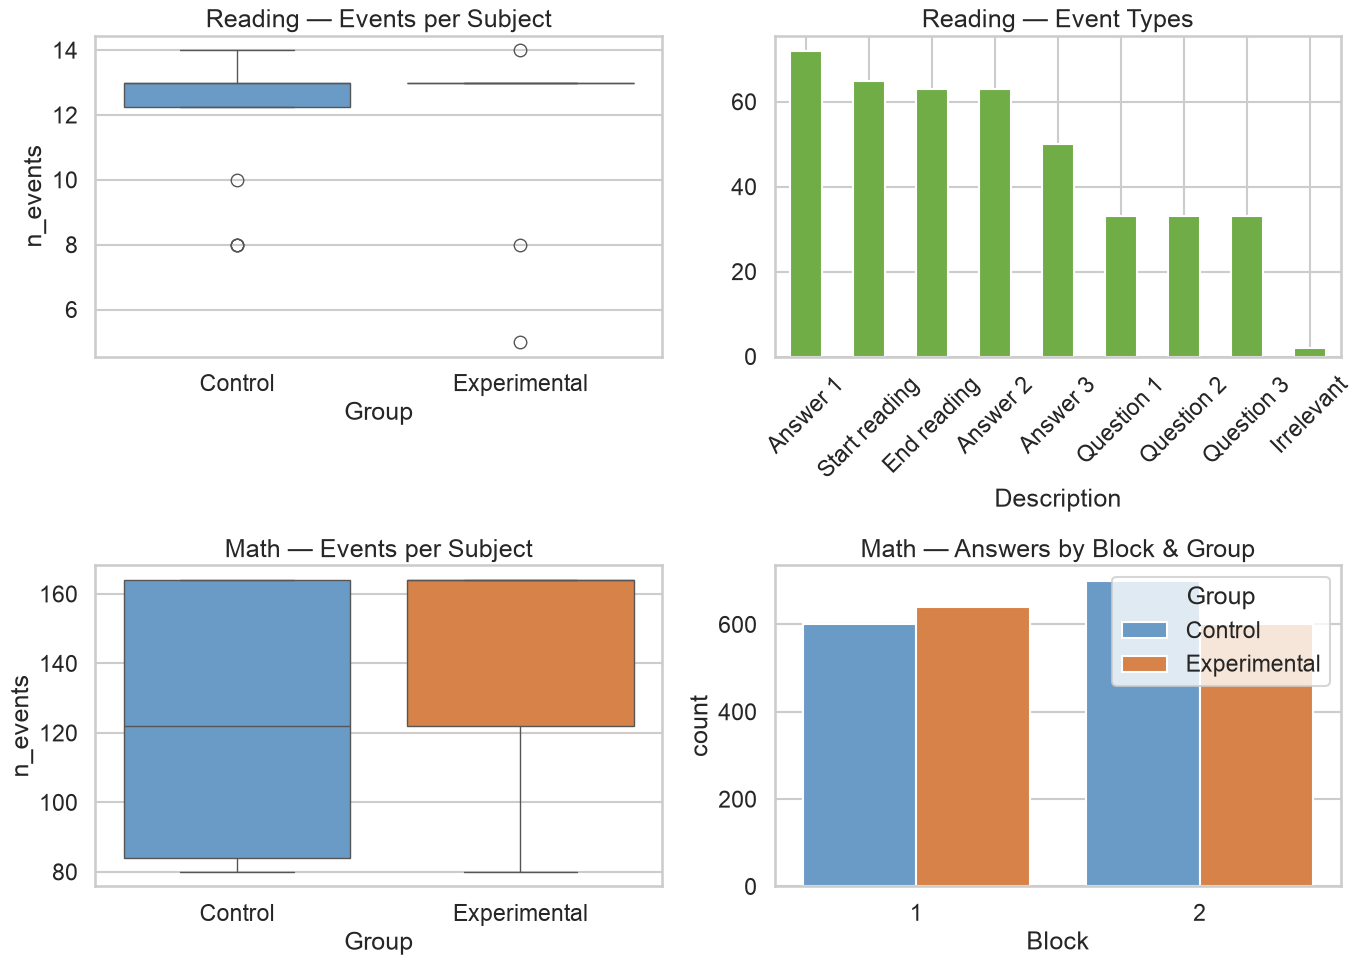

In [93]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Reading: events per subject
events_per_subj_r = rt.groupby("Subject").size().reset_index(name="n_events")
events_per_subj_r = events_per_subj_r.merge(
    rt[["Subject", "Group"]].drop_duplicates(), on="Subject")
sns.boxplot(data=events_per_subj_r, x="Group", y="n_events", ax=axes[0, 0],
            palette={"Control": "#5B9BD5", "Experimental": "#ED7D31"})
axes[0, 0].set_title("Reading — Events per Subject")

# Reading: description counts
rt["Description"].value_counts().plot(kind="bar", ax=axes[0, 1], color="#70AD47")
axes[0, 1].set_title("Reading — Event Types")
axes[0, 1].tick_params(axis="x", rotation=45)

# Math: events per subject
events_per_subj_m = mt.groupby("Subject").size().reset_index(name="n_events")
events_per_subj_m = events_per_subj_m.merge(
    mt[["Subject", "Group"]].drop_duplicates(), on="Subject")
sns.boxplot(data=events_per_subj_m, x="Group", y="n_events", ax=axes[1, 0],
            palette={"Control": "#5B9BD5", "Experimental": "#ED7D31"})
axes[1, 0].set_title("Math — Events per Subject")

# Math: Answer distribution by block
ans = mt[mt["Description"].str.startswith("Answer")]
sns.countplot(data=ans, x="Block", hue="Group", ax=axes[1, 1],
              palette={"Control": "#5B9BD5", "Experimental": "#ED7D31"})
axes[1, 1].set_title("Math — Answers by Block & Group")

fig.tight_layout()
fig.savefig(OUT / "event_tags_structure.png", dpi=150, bbox_inches="tight")
plt.show()

---
## 6. Engagement ↔ Psychometrics

In [94]:
def merge_engagement(df_psy, eng, dvs, label):
    """Merge engagement with change scores for experimental subjects."""
    psy_exp = df_psy[df_psy.Subgroup == "E"].copy()
    merged = psy_exp.merge(eng, left_on="Subject", right_on="Subject")
    print(f"\n{label}: {len(merged)} experimental subjects with engagement data")
    results = []
    for dv in dvs:
        delta = merged[f"{dv}_POST"] - merged[f"{dv}_PRE"]
        rho, p = stats.spearmanr(merged["Engagement"], delta)
        results.append({"DV": dv, "Spearman_r": rho, "p": p})
    return pd.DataFrame(results), merged

eng = pd.read_excel(ROOT / "05_SessionEngagement.xlsx")
eng = eng[["Subject", "Smartick program", "Session Engagement (%)"]].copy()
eng.columns = ["Subject", "Program", "Engagement"]

In [95]:
res_r, merged_r = merge_engagement(df_reading, eng, reading_dvs, "Reading")
res_r.to_csv(OUT / "engagement_corr_reading.csv", index=False)
res_r


Reading: 19 experimental subjects with engagement data


,DV,Spearman_r,p
0,Orthographic_ERR,-0.122674,0.616852
1,Phonological_ERR,0.092030,0.707873
2,Selective_Attention,-0.057761,0.814305
3,Reading_Speed,-0.189807,0.436395
4,Comprehension,-0.153408,0.530645


In [96]:
res_m, merged_m = merge_engagement(df_math, eng, math_dvs, "Math")
res_m.to_csv(OUT / "engagement_corr_math.csv", index=False)
res_m


Math: 17 experimental subjects with engagement data


,DV,Spearman_r,p
0,WRAT4,0.473264,0.055013
1,hits,0.331898,0.193094
2,RT,0.371779,0.141723
3,Selective_Attention,0.470445,0.056680


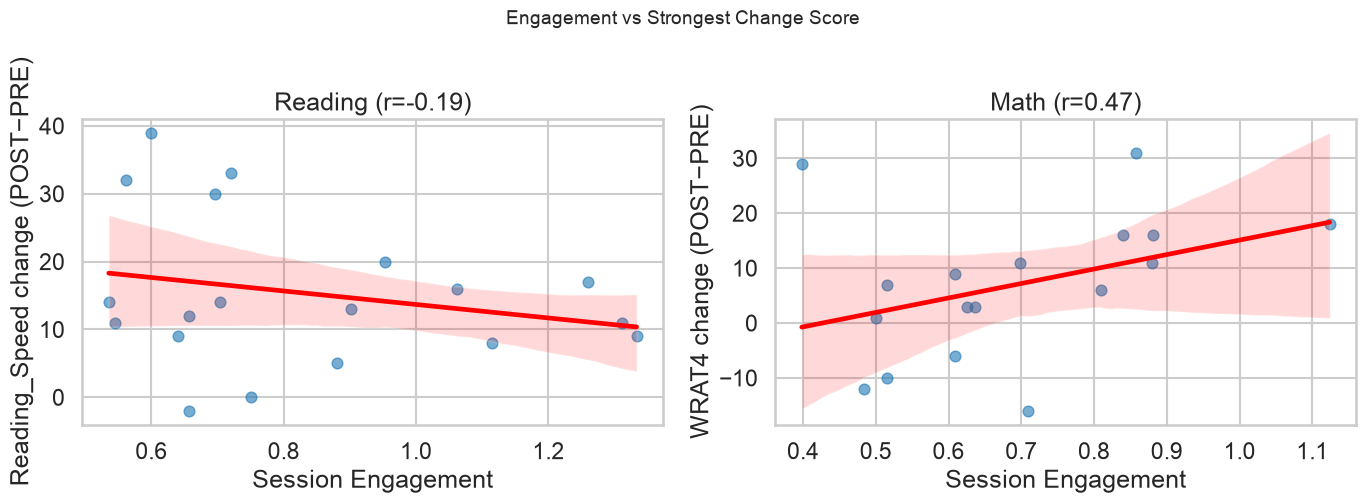

In [97]:
# Scatter: engagement vs top change score for each cohort
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (name, merged, dvs) in zip(axes, [("Reading", merged_r, reading_dvs),
                                           ("Math", merged_m, math_dvs)]):
    # pick DV with strongest correlation
    best_dv = None
    best_rho = 0
    for dv in dvs:
        delta = merged[f"{dv}_POST"] - merged[f"{dv}_PRE"]
        rho, _ = stats.spearmanr(merged["Engagement"], delta)
        if abs(rho) > abs(best_rho):
            best_rho = rho
            best_dv = dv
    delta = merged[f"{best_dv}_POST"] - merged[f"{best_dv}_PRE"]
    sns.regplot(x=merged["Engagement"], y=delta, ax=ax,
                scatter_kws={"alpha": 0.6, "s": 60}, line_kws={"color": "red"})
    ax.set_xlabel("Session Engagement")
    ax.set_ylabel(f"{best_dv} change (POST\u2212PRE)")
    ax.set_title(f"{name} (r={best_rho:.2f})")

fig.suptitle("Engagement vs Strongest Change Score", fontsize=14, y=1.02)
fig.tight_layout()
fig.savefig(OUT / "engagement_vs_change.png", dpi=150, bbox_inches="tight")
plt.show()

---
## 7. Recording Metadata Consistency

In [98]:
# Parse all _eeg.json sidecars
records = []
for jf in sorted(ROOT.rglob("*_eeg.json")):
    with open(jf) as f:
        meta = json.load(f)
    parts = jf.stem.split("_")
    records.append({
        "Subject": parts[0],
        "Session": parts[1] if len(parts) > 1 else "",
        "SamplingFreq": meta.get("SamplingFrequency"),
        "NChannels": meta.get("EEGChannelCount"),
        "Duration": meta.get("RecordingDuration"),
        "PowerLine": meta.get("PowerLineFrequency"),
        "EEGRef": meta.get("EEGReference"),
        "Manufacturer": meta.get("ManufacturersModelName"),
        "Cap": meta.get("CapManufacturer"),
    })
meta_df = pd.DataFrame(records)

print(f"Total sidecar files parsed: {len(meta_df)}")
print(f"Unique subjects: {meta_df.Subject.nunique()}")
print(f"\nSamplingFrequency: {meta_df.SamplingFreq.unique()}")
print(f"EEGChannelCount: {meta_df.NChannels.unique()}")
print(f"RecordingDuration (sec): {meta_df.Duration.unique()}")
print(f"PowerLineFrequency: {meta_df.PowerLine.unique()}")
print(f"EEGReference: {meta_df.EEGRef.unique()}")
print(f"Manufacturer: {meta_df.Manufacturer.unique()}")
print(f"CapManufacturer: {meta_df.Cap.unique()}")

meta_df.to_csv(OUT / "recording_metadata_summary.csv", index=False)

Total sidecar files parsed: 365
Unique subjects: 76

SamplingFrequency: [256]
EEGChannelCount: [32]
RecordingDuration (sec): [ 180.          296.27734375  201.34765625   72.43359375   76.31640625
   76.59765625   99.69140625  357.87109375  326.31640625  254.22265625
  324.87890625  205.15234375  169.03515625  333.87890625  309.87890625
  151.83984375  255.44140625  151.81640625  189.22265625  319.93359375
  267.06640625  305.78515625  265.47265625  479.62109375  531.03515625
  633.50390625  512.87890625  390.74609375  552.59765625  143.27734375
  184.84765625  114.62890625  128.44140625  180.00390625  140.96484375
  162.41015625  177.97265625  181.81640625  199.33984375  228.31640625
  358.37890625  217.34765625  263.77734375  268.44140625  346.84765625
  316.44140625  201.65234375  204.00390625  189.66015625  131.09765625
 1059.02734375 1112.59765625  224.40234375  311.69140625  374.37109375
  240.00390625  244.97265625  223.91015625  256.40234375  218.41015625
  264.05078125  196.753

---
## Done

All figures and tables saved to `analysis/results/eda/`.